# Homework 6: Non-negative FIR Filter Design
## Name: Jon Knapp
### Date: November 10, 2026
### Class: EE 522 Discrete Time Processing

## AI Disclosure:

AI was used in the following ways:
* Code generation
* Markdown generation
* Checking my work and my logic
* Process suggestions
* Project analysis to fit non-negative FIR filters

## Problem 1: Select three different non-causal, non-negative impulse responses with even symmetry. The purpose of these filters is to smooth the signals they are applied to, where the amount of smoothing is controlled by the duration of the impulse response. Please scale the impulse responses for a DC gain of 1. Give a mathematical or verbal description of each impulse response, and provide your rationale for using this impulse response.

Each filter is non-causal and centered at $n = 0$, defined on $-M \le n \le M$ with length $N = 2M + 1$.
All three satisfy:

- **Non-negative:** $h[n] \ge 0$ for all $n$
- **Even symmetry:** $h[n] = h[-n]$
- **Unit DC gain:** $H(e^{j0}) = \sum_{n=-M}^{M} h[n] = 1$

The half-length $M$ sets the duration of the impulse response, and therefore the amount of smoothing.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import comb
from matplotlib.ticker import MaxNLocator

plt.style.use("default")   # white-background figures regardless of editor theme


def rectangular(M):
    # Moving average (boxcar): 2M+1 equal taps, each 1/(2M+1).
    n = np.arange(-M, M + 1)
    h = np.ones_like(n, dtype=float) / (2 * M + 1)
    return n, h


def triangular(M):
    # Bartlett: linear taper from the center, zero just outside |n| = M.
    n = np.arange(-M, M + 1)
    h = (M + 1 - np.abs(n)) / (M + 1) ** 2
    return n, h


def binomial(M):
    # Binomial: row 2M of Pascal's triangle, scaled by 2^(-2M).
    n = np.arange(-M, M + 1)
    h = comb(2 * M, M + n, exact=False) / 2.0 ** (2 * M)
    return n, h


def check_filter(name, n, h):
    # Confirm the three required properties numerically.
    print(f"{name:12s}  N = {len(h):3d}   sum(h) = {h.sum():.12f}   "
          f"min(h) = {h.min():.3e}   symmetric = {np.allclose(h, h[::-1])}")


def plot_impulse(n, h, title, ax=None):
    if ax is None:
        _, ax = plt.subplots(figsize=(8, 3.5))
    ax.stem(n, h, basefmt="k-")
    ax.set_xlabel("Sample index $n$")
    ax.set_ylabel("$h[n]$")
    ax.set_title(title)
    ax.grid(True, alpha=0.3)
    ax.set_ylim(bottom=0)
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    return ax


M = 10   # half-length used for the example plots below (N = 21)

### Filter 1: Rectangular (moving average / boxcar)

$$
h_{\text{rect}}[n] =
\begin{cases}
\dfrac{1}{2M+1}, & |n| \le M \\[6pt]
0, & \text{otherwise}
\end{cases}
$$

Every sample in the window receives equal weight, so the output is the arithmetic mean of the $2M+1$ input samples centered on $n$.

**DC gain:** $\displaystyle\sum_{n=-M}^{M} \frac{1}{2M+1} = \frac{2M+1}{2M+1} = 1$

**Frequency response** (a real-valued Dirichlet kernel, so zero phase):

$$
H_{\text{rect}}(e^{j\omega}) = \frac{1}{2M+1}\,\frac{\sin\!\big(\omega(2M+1)/2\big)}{\sin(\omega/2)}
$$

**Rationale:** The simplest possible smoother and the baseline for comparison. For a given length it has the narrowest main lobe, but its sidelobes are high (about $-13$ dB) and alternate in sign, so some high-frequency content leaks through.

Rectangular   N =  21   sum(h) = 1.000000000000   min(h) = 4.762e-02   symmetric = True


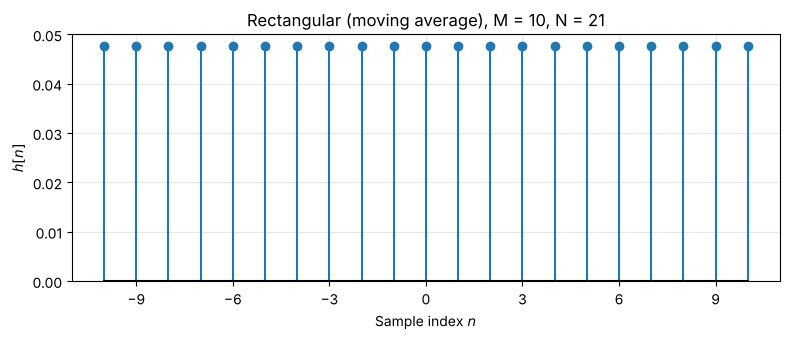

In [2]:
n, h_rect = rectangular(M)
check_filter("Rectangular", n, h_rect)
plot_impulse(n, h_rect, f"Rectangular (moving average), M = {M}, N = {2*M+1}")
plt.tight_layout()
plt.show()

### Filter 2: Triangular (Bartlett)

$$
h_{\text{tri}}[n] =
\begin{cases}
\dfrac{M+1-|n|}{(M+1)^2}, & |n| \le M \\[6pt]
0, & \text{otherwise}
\end{cases}
$$

The weights fall off linearly from a peak of $\frac{1}{M+1}$ at $n = 0$ and reach zero at $|n| = M+1$, so all $2M+1$ taps in the window are strictly positive.

**DC gain:**
$$
\sum_{n=-M}^{M} (M+1-|n|) = (M+1) + 2\sum_{k=1}^{M}(M+1-k) = (M+1) + M(M+1) = (M+1)^2
$$
so dividing by $(M+1)^2$ gives a sum of 1.

**Frequency response:** The triangle equals the convolution of two length-$(M+1)$ rectangles, $h_{\text{tri}} = h_{\text{rect},M+1} * h_{\text{rect},M+1}$, so its response is the square of a Dirichlet kernel:

$$
H_{\text{tri}}(e^{j\omega}) = \left[\frac{1}{M+1}\,\frac{\sin\!\big(\omega(M+1)/2\big)}{\sin(\omega/2)}\right]^2 \ge 0
$$

**Rationale:** Tapering the edges trades a wider main lobe for much lower sidelobes (about $-26$ dB), and because $H_{\text{tri}}(e^{j\omega})$ is never negative, the filter never inverts the sign of any frequency component.

Triangular    N =  21   sum(h) = 1.000000000000   min(h) = 8.264e-03   symmetric = True


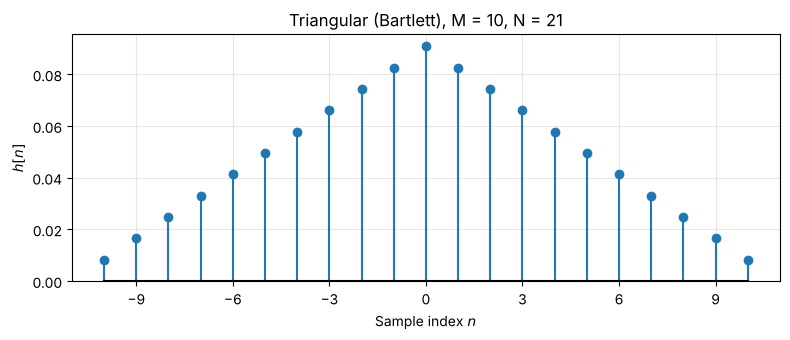

In [3]:
n, h_tri = triangular(M)
check_filter("Triangular", n, h_tri)
plot_impulse(n, h_tri, f"Triangular (Bartlett), M = {M}, N = {2*M+1}")
plt.tight_layout()
plt.show()

### Filter 3: Binomial

$$
h_{\text{bin}}[n] =
\begin{cases}
\dfrac{1}{2^{2M}}\dbinom{2M}{M+n}, & |n| \le M \\[6pt]
0, & \text{otherwise}
\end{cases}
$$

The taps are row $2M$ of Pascal's triangle. Equivalently, $h_{\text{bin}}$ is the two-tap average $\left[\tfrac12, \tfrac12\right]$ convolved with itself $2M$ times (then centered at $n = 0$).

**DC gain:** By the binomial theorem,
$$
\sum_{k=0}^{2M}\binom{2M}{k} = (1+1)^{2M} = 2^{2M}
$$
so dividing by $2^{2M}$ gives a sum of exactly 1.

**Frequency response:** Each $\left[\tfrac12,\tfrac12\right]$ stage contributes a factor $\cos(\omega/2)$ (after removing its half-sample delay), so

$$
H_{\text{bin}}(e^{j\omega}) = \cos^{2M}\!\left(\frac{\omega}{2}\right)
$$

which is real, non-negative, and decreases monotonically from 1 at $\omega = 0$ to 0 at $\omega = \pi$.

**Rationale:** By the central limit theorem the binomial taps approach a Gaussian as $M$ grows, giving a very smooth lowpass response with no sidelobes and no ripple. The cost is a gradual transition band. Note that its effective width is narrower than its support: the standard deviation is $\sigma = \sqrt{M/2}$ samples, so a binomial filter needs a larger $M$ than the rectangle to reach the same cutoff.

Binomial      N =  21   sum(h) = 1.000000000000   min(h) = 9.537e-07   symmetric = True


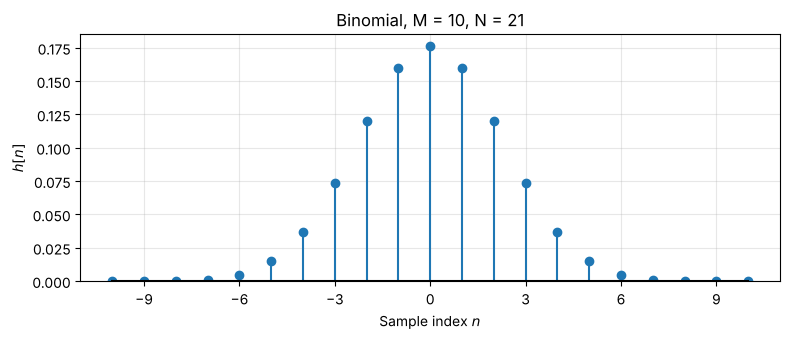

In [4]:
n, h_bin = binomial(M)
check_filter("Binomial", n, h_bin)
plot_impulse(n, h_bin, f"Binomial, M = {M}, N = {2*M+1}")
plt.tight_layout()
plt.show()

### Side-by-side comparison

All three filters with the same half-length $M$. Note the different vertical scales: the taps in each filter always sum to 1, so a more concentrated filter has a taller peak.

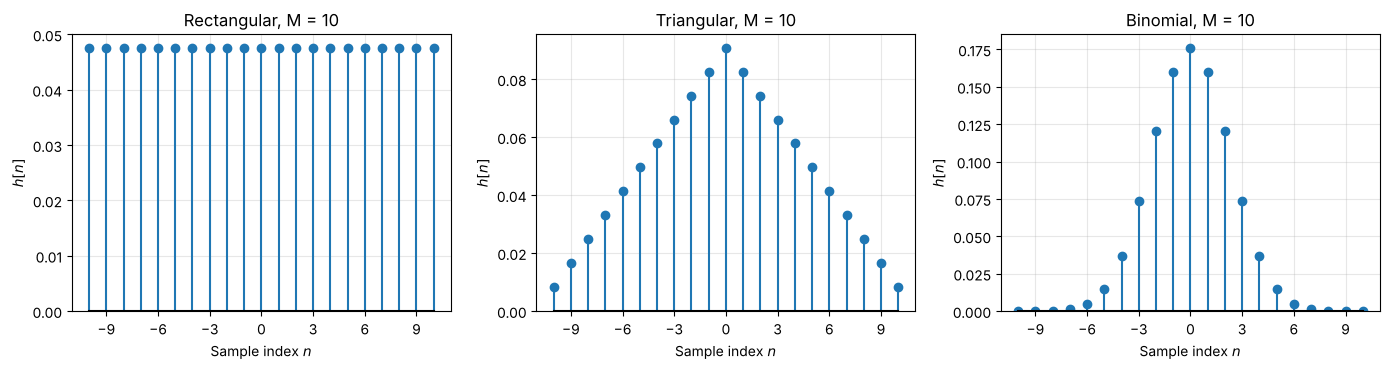

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
for ax, (name, fn) in zip(axes, [("Rectangular", rectangular),
                                 ("Triangular", triangular),
                                 ("Binomial", binomial)]):
    n, h = fn(M)
    plot_impulse(n, h, f"{name}, M = {M}", ax=ax)
plt.tight_layout()
plt.show()

## Problem 2: For each of the three filters, provide the following:
* An explanation of how you enforce the requirement that the DC gain is 1
* A plot that shows how the cutoff frequency of the filter is related to the duration of the filter
* For each of the cutoff frequencies of 0.05 pi, 0.1 pi, and 0.2 pi, include the following in your report:
  * Magnitude response
  * Phase response
  * Group delay
  * Impulse response
  * Time domain example of the input and output signals applied to the following signals. Please include the input and output signals on the same plot with clear labels that make it clear which signal is the input and which is the output.
    * A white noise, signal with 200 samples, a mean of 1, and a variance of 1. Be mindful of edge conditions.
    * A shifted step x[n] = u[n-100] with 200 samples. Be mindful of edge conditions.
    * 100 samples of a sinusoid with a frequency of 0.1 pi radians per sample.
  * Power spectral density plot of the input signal
  * Power spectral density plot of the output signal


### _An explanation of how you enforce the requirement that the DC gain is 1_

### Filter 1: Rectangular (moving average / boxcar)

$$
h_{\text{rect}}[n] =
\begin{cases}
\dfrac{1}{2M+1}, & |n| \le M \\[6pt]
0, & \text{otherwise}
\end{cases}
$$

**DC gain:** $\displaystyle\sum_{n=-M}^{M} \frac{1}{2M+1} = \frac{2M+1}{2M+1} = 1$

### Filter 2: Triangular (Bartlett)

$$
h_{\text{tri}}[n] =
\begin{cases}
\dfrac{M+1-|n|}{(M+1)^2}, & |n| \le M \\[6pt]
0, & \text{otherwise}
\end{cases}
$$

**DC gain:**
$$
\sum_{n=-M}^{M} (M+1-|n|) = (M+1) + 2\sum_{k=1}^{M}(M+1-k) = (M+1) + M(M+1) = (M+1)^2
$$
so dividing by $(M+1)^2$ gives a sum of 1.

### Filter 3: Binomial

$$
h_{\text{bin}}[n] =
\begin{cases}
\dfrac{1}{2^{2M}}\dbinom{2M}{M+n}, & |n| \le M \\[6pt]
0, & \text{otherwise}
\end{cases}
$$

**DC gain:** By the binomial theorem,
$$
\sum_{k=0}^{2M}\binom{2M}{k} = (1+1)^{2M} = 2^{2M}
$$
so dividing by $2^{2M}$ gives a sum of exactly 1.

### _A plot that shows how the cutoff frequency of the filter is related to the duration of the filter_

**Cutoff definition.** I use the $-3$ dB (half-power) frequency: the smallest $\omega_c > 0$ where
$$
|H(e^{j\omega_c})| = \frac{1}{\sqrt{2}}.
$$
Because each $h[n]$ is even-symmetric about $n = 0$, the frequency response is purely real:
$$
H(e^{j\omega}) = h[0] + 2\sum_{n=1}^{M} h[n]\cos(\omega n),
$$
so I evaluate it on a dense grid over $[0, \pi]$, find the first grid point that drops below $1/\sqrt{2}$, and refine the crossing with a root finder.

**Duration** is the number of taps, $N = 2M + 1$. Since $M$ must be an integer, only a discrete set of cutoffs is achievable, so for each target cutoff I pick the $M$ whose cutoff is closest.

In [6]:
from scipy.optimize import brentq


def amplitude_response(h, M, w):
    # Real (zero-phase) response of an even-symmetric filter centered at n = 0.
    k = np.arange(1, M + 1)
    return h[M] + 2 * np.cos(np.outer(w, k)) @ h[M + 1:]


def cutoff_3dB(filter_fn, M, n_grid=8192):
    # First frequency (rad/sample) where |H| falls to 1/sqrt(2).
    _, h = filter_fn(M)
    level = 1 / np.sqrt(2)
    w = np.linspace(0, np.pi, n_grid)
    A = amplitude_response(h, M, w)
    i = np.argmax(np.abs(A) < level)          # first grid point below the level
    f = lambda x: amplitude_response(h, M, np.array([x]))[0] - level
    return brentq(f, w[i - 1], w[i])


filters = {"Rectangular": rectangular,
           "Triangular": triangular,
           "Binomial": binomial}

M_range = np.arange(1, 121)
N_range = 2 * M_range + 1
cutoffs = {name: np.array([cutoff_3dB(fn, M) for M in M_range])
           for name, fn in filters.items()}

targets = np.array([0.05, 0.1, 0.2]) * np.pi

### Cutoff vs. duration for each filter

Each plot shows the $-3$ dB cutoff (in units of $\pi$) against the filter length $N$. The dashed lines mark the three target cutoffs, and the marked points are the lengths that come closest to each target.

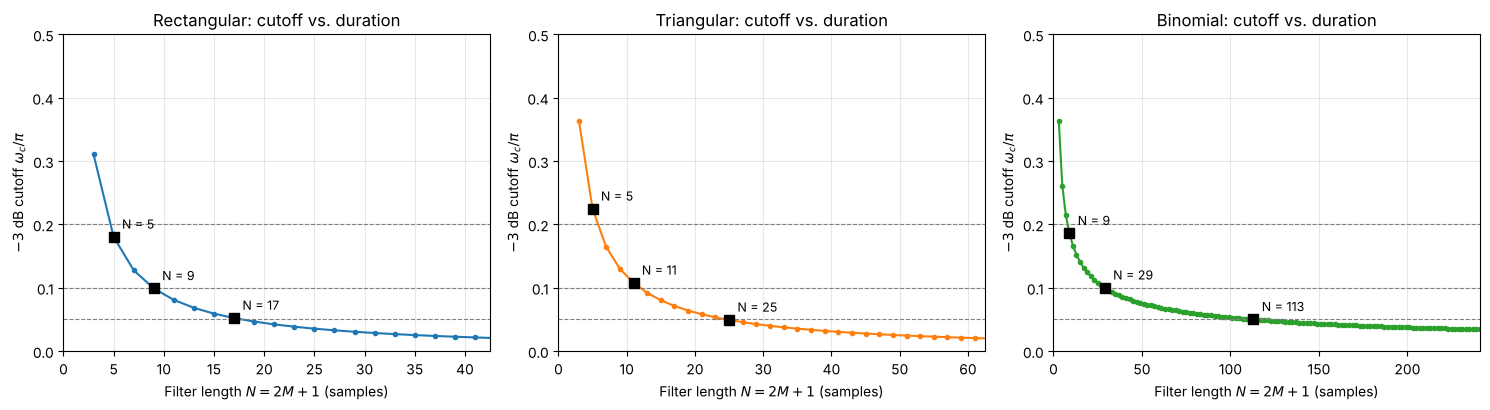

In [7]:
colors = {"Rectangular": "C0", "Triangular": "C1", "Binomial": "C2"}
design = {}   # chosen M for each (filter, target), used in the rest of Problem 2

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for ax, name in zip(axes, filters):
    wc = cutoffs[name]
    ax.plot(N_range, wc / np.pi, "o-", ms=3, color=colors[name], label="$\\omega_c$")
    design[name] = {}
    for wt in targets:
        i = np.argmin(np.abs(wc - wt))
        design[name][wt / np.pi] = M_range[i]
        ax.axhline(wt / np.pi, color="gray", ls="--", lw=0.8)
        ax.plot(N_range[i], wc[i] / np.pi, "ks", ms=7)
        ax.annotate(f"N = {N_range[i]}", (N_range[i], wc[i] / np.pi),
                    textcoords="offset points", xytext=(6, 6), fontsize=9)
    ax.set_title(f"{name}: cutoff vs. duration")
    ax.set_xlabel("Filter length $N = 2M + 1$ (samples)")
    ax.set_ylabel("$-3$ dB cutoff $\\omega_c / \\pi$")
    ax.set_ylim(0, 0.5)
    N_max = 2 * max(design[name].values()) + 1
    ax.set_xlim(0, min(2.5 * N_max, N_range[-1]))   # zoom to the region of interest
    ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### All three filters on log-log axes

On log-log axes a power law $\omega_c \propto N^{p}$ is a straight line with slope $p$. The rectangular and triangular filters fall off as roughly $1/N$, while the binomial filter falls off as roughly $1/\sqrt{N}$. This follows from its response $\cos^{2M}(\omega/2) \approx e^{-M\omega^2/4}$ for small $\omega$, which gives $\omega_c \approx \sqrt{2\ln 2 / M}$. The practical consequence is that the binomial filter needs a much longer impulse response to reach a low cutoff.

Rectangular  fitted slope of log(wc) vs log(N): -1.000
Triangular   fitted slope of log(wc) vs log(N): -0.988
Binomial     fitted slope of log(wc) vs log(N): -0.506


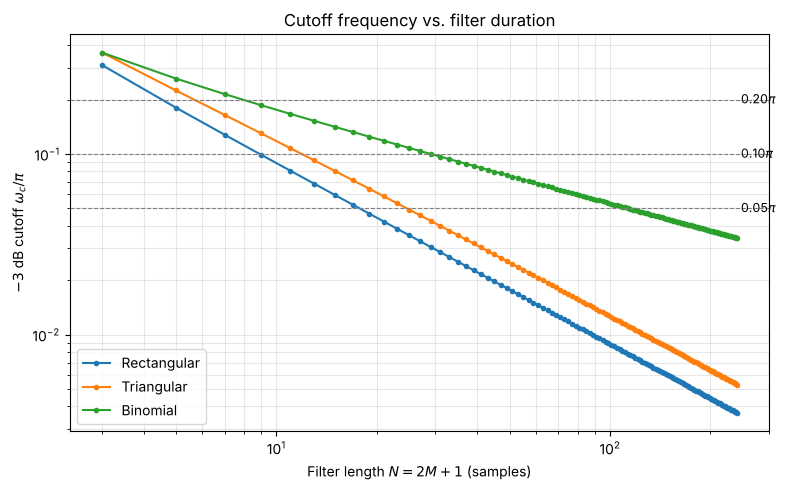

In [8]:
fig, ax = plt.subplots(figsize=(8, 5))
for name in filters:
    wc = cutoffs[name]
    ax.loglog(N_range, wc / np.pi, "o-", ms=3, color=colors[name], label=name)
    # Fitted slope over the longer filters, where the asymptotic behavior holds
    sel = M_range >= 10
    slope = np.polyfit(np.log(N_range[sel]), np.log(wc[sel]), 1)[0]
    print(f"{name:12s} fitted slope of log(wc) vs log(N): {slope:+.3f}")
for wt in targets:
    ax.axhline(wt / np.pi, color="gray", ls="--", lw=0.8)
    ax.text(N_range[-1], wt / np.pi, f" {wt/np.pi:.2f}$\\pi$", va="center", fontsize=9)
ax.set_xlabel("Filter length $N = 2M + 1$ (samples)")
ax.set_ylabel("$-3$ dB cutoff $\\omega_c / \\pi$")
ax.set_title("Cutoff frequency vs. filter duration")
ax.grid(True, which="both", alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

### Filter lengths chosen for each target cutoff

In [9]:
print(f"{'Filter':12s} {'Target':>8s} {'M':>5s} {'N':>5s} {'Actual wc/pi':>14s} {'Error':>8s}")
for name, fn in filters.items():
    for target, M_sel in design[name].items():
        wc = cutoff_3dB(fn, M_sel) / np.pi
        print(f"{name:12s} {target:7.2f}π {M_sel:5d} {2*M_sel+1:5d} "
              f"{wc:13.4f}π {100*(wc-target)/target:+7.1f}%")

Filter         Target     M     N   Actual wc/pi    Error
Rectangular     0.05π     8    17        0.0522π    +4.4%
Rectangular     0.10π     4     9        0.0990π    -1.0%
Rectangular     0.20π     2     5        0.1803π    -9.8%
Triangular      0.05π    12    25        0.0492π    -1.6%
Triangular      0.10π     5    11        0.1077π    +7.7%
Triangular      0.20π     2     5        0.2245π   +12.3%
Binomial        0.05π    56   113        0.0501π    +0.1%
Binomial        0.10π    14    29        0.1000π    -0.0%
Binomial        0.20π     4     9        0.1860π    -7.0%


For each filter and target cutoff, I use the length $N = 2M + 1$ selected above and show three figures:

1. **Filter characteristics:** impulse response, magnitude response, phase response, and group delay.
2. **Time-domain examples:** input and output on the same axes for white noise, the shifted step, and the sinusoid.
3. **Power spectral densities:** input and output PSD for each of the three test signals.

### Phase and group delay

The filters are non-causal and even-symmetric about $n = 0$, so $H(e^{j\omega}) = A(\omega)$ is purely real. The phase is therefore
$$
\angle H(e^{j\omega}) =
\begin{cases}
0, & A(\omega) > 0 \\
\pm\pi, & A(\omega) < 0
\end{cases}
$$
and the group delay $\tau_g(\omega) = -\dfrac{d\angle H}{d\omega}$ is **zero** at every frequency (the $\pi$ jumps happen at zeros of $H$, where group delay is undefined). The triangular and binomial filters have $A(\omega) \ge 0$, so their phase is identically zero; the rectangular filter's negative sidelobes produce $\pi$ jumps.

If the filter were instead implemented causally as $h_c[n] = h[n - M]$, the phase would become $\angle H(e^{j\omega}) - M\omega$ and the group delay a constant $M$ samples. The group delay plots show both for comparison.

Phase and group delay are left blank where $|H(e^{j\omega})|$ falls below $-200$ dB. There the response is numerically zero in double precision, so its sign (and therefore the phase) is roundoff noise and the computed group delay is unreliable. This only affects the long binomial filters at high frequencies.

### Edge handling

At each end of the signal, the $2M + 1$-sample window extends past the available data. Zero-padding would treat the missing samples as zeros and pull the output toward zero near the edges, which is badly wrong for the mean-1 noise and the step. Instead I use **normalized convolution**: at each output sample, the filter is applied only to the input samples that exist, and the result is divided by the sum of the filter taps actually used,
$$
y[n] = \frac{\sum_{k} h[k]\,x[n-k]}{\sum_{k} h[k]}, \qquad \text{sums over } k \text{ with } 0 \le n-k \le L-1 .
$$
Because $h[n] \ge 0$, the denominator is always positive, so this is a valid weighted average everywhere and the DC gain stays exactly 1 even at the edges. Away from the edges the denominator is 1 and this is ordinary convolution. The shaded regions on the time-domain plots mark the $M$ samples at each end where the window is truncated.

### PSD estimation

Every PSD is the **periodogram** of the entire record: one FFT over all $L$ samples ($L = 200$ for the noise and the step, $L = 100$ for the sinusoid), with no segmenting and no averaging. I do not use Welch's method. Splitting the step $u[n-100]$ into short segments gives some all-zero segments, some all-one segments, and at most one segment containing the transition. Averaging those does not give the spectrum of the step. For consistency, the same estimator is used for all signals.

The periodogram is a scaled FFT. Let $X[k]$ be the $N_{\text{FFT}}$-point FFT of $x[n]$ with no taper (a rectangular window). The one-sided PSD in power per rad/sample is
$$
\hat{P}(\omega_k) = \frac{c_k\,|X[k]|^2}{2\pi L}, \qquad \omega_k = \frac{2\pi k}{N_{\text{FFT}}}, \qquad
c_k =
\begin{cases}
1, & \omega_k = 0 \text{ or } \pi \\
2, & 0 < \omega_k < \pi
\end{cases}
$$
Dividing by $2\pi L$ makes the area under the PSD equal to the signal's average power $\frac{1}{L}\sum_n x^2[n]$ (Parseval's relation), and $c_k = 2$ folds the negative frequencies onto the positive ones. The check below confirms both numerically. Each record is zero-padded to $N_{\text{FFT}} = 1024$ points. This only samples the same DTFT on a finer grid so the curves are smooth. It adds no resolution (resolution is set by $L$), and it does no averaging. The mean is **not** removed, so the DC component of the noise and the step is visible. For the white-noise input, the dashed lines show the theoretical PSDs: $\sigma^2/\pi$ for the input and $|H(e^{j\omega})|^2\,\sigma^2/\pi$ for the output (one-sided, per rad/sample).

**Reading the periodogram plots**

- **White noise:** a single periodogram is not averaged, so its variance does not shrink as $L$ grows. At each frequency the estimate fluctuates by about as much as its own mean, so swings of $\pm 10$ dB around the theoretical line are normal. The output follows the shape of $|H|^2\sigma^2/\pi$ on average, not point by point.
- **Leakage floor:** with no taper, the window is rectangular. Its sidelobes start at only $-13$ dB and fall off at just 6 dB per octave. The noise has a mean of 1, so a large DC component leaks across the whole band and puts a floor near $-30$ dB under the output PSD. Where the estimated output PSD sits above the theory at high frequencies (most visible for the binomial and triangular filters), that floor is a limit of the estimator, not of the filter.
- **Shifted step:** the DTFT of the finite record assumes zeros outside $0 \le n \le 199$. The input therefore has two unit jumps: up at $n = 100$ and back down to zero after $n = 199$. In effect, the periodogram sees one period of a square wave. The two jumps interfere, which produces the closely spaced nulls (every $0.02\pi$) under a $1/\sin^2(\omega/2)$ envelope. The filter smooths the jump at $n = 100$ into a ramp, which removes that edge's high-frequency content. Only the jump at the end of the record remains, so the output PSD is a smooth curve without nulls, about 6 dB below the input's peaks.
- **Sinusoid:** the 100 samples contain exactly 5 cycles of $0.1\pi$, so the input PSD peaks at $\omega = 0.1\pi$. The sidelobes around it are the rectangular window's sinc pattern, made visible by the zero padding. The output peak is scaled by $|H(e^{j0.1\pi})|^2$. It is strongly attenuated when the cutoff is below $0.1\pi$, and passes almost unchanged when the cutoff is $0.2\pi$.


In [10]:
import warnings
from scipy.signal import periodogram, group_delay

# ---- Test signals (one fixed noise realization, reused for every design) ----
rng = np.random.default_rng(42)
L_long = 200
z = rng.standard_normal(L_long)
x_noise = 1.0 + (z - z.mean()) / z.std(ddof=1)            # exactly mean 1, variance 1
x_step = (np.arange(L_long) >= 100).astype(float)          # u[n - 100]
x_sine = np.cos(0.1 * np.pi * np.arange(100))              # 0.1*pi rad/sample

test_signals = [("White noise (mean 1, var 1)", x_noise),
                ("Shifted step $u[n-100]$", x_step),
                ("Sinusoid, $\\omega_0 = 0.1\\pi$", x_sine)]

# ---- PSD settings: periodogram over the entire record (no segmenting or averaging) ----
NFFT_PSD = 1024                                    # zero-pad only to sample the DTFT finely
PSD_KW = dict(fs=2 * np.pi, window="boxcar", nfft=NFFT_PSD, detrend=False,
              return_onesided=True, scaling="density")

w_grid = np.linspace(0, np.pi, 4096)


def apply_filter(x, h):
    # Non-causal filtering with normalized convolution at the edges.
    M = (len(h) - 1) // 2
    L = len(x)
    num = np.convolve(x, h)[M:M + L]               # centered (zero-phase) output
    den = np.convolve(np.ones(L), h)[M:M + L]      # sum of taps that overlap the data
    return num / den


def psd_db(x):
    # Periodogram of the whole signal: P(w) = |X(e^jw)|^2 / (2*pi*L), doubled for 0 < w < pi
    f, P = periodogram(x, **PSD_KW)                # f in rad/sample, 0 to pi
    return f, 10 * np.log10(np.maximum(P, 1e-12))


def shade_edges(ax, L, M):
    edge = min(M, L / 2)
    ax.axvspan(-0.5, edge - 0.5, color="gray", alpha=0.15, lw=0)
    ax.axvspan(L - edge - 0.5, L - 0.5, color="gray", alpha=0.15, lw=0,
               label="Edge region (window truncated)")


def report_design(name, target):
    fn = filters[name]
    key = min(design[name], key=lambda t: abs(t - target))   # float-safe lookup
    M = design[name][key]
    n, h = fn(M)
    wc = cutoff_3dB(fn, M)
    tag = f"{name}, target $\\omega_c = {target:g}\\pi$ (M = {M}, N = {2*M+1}, actual $\\omega_c = {wc/np.pi:.4f}\\pi$)"

    # ---------- Figure 1: filter characteristics ----------
    A = amplitude_response(h, M, w_grid)
    mag_db = 20 * np.log10(np.maximum(np.abs(A), 1e-6))
    tiny = np.abs(A) < 1e-10                       # below -200 dB: numerically zero
    phase = np.where(A < 0, np.pi, 0.0)            # angle of a real-valued response
    phase[tiny] = np.nan

    h_causal = h                                   # same taps, indexed 0..2M
    with warnings.catch_warnings(), np.errstate(all="ignore"):
        warnings.simplefilter("ignore")
        _, gd_causal = group_delay((h_causal, [1.0]), w=w_grid)
    gd_causal[tiny] = np.nan                       # unreliable where |H| is ~0
    gd_noncausal = gd_causal - M

    fig, ax = plt.subplots(2, 2, figsize=(13, 7.5))
    fig.suptitle(f"Filter characteristics: {tag}", fontsize=12)

    a = ax[0, 0]
    a.stem(n, h, basefmt="k-")
    a.set_title("Impulse response $h[n]$")
    a.set_xlabel("Sample index $n$")
    a.set_ylabel("$h[n]$")
    a.set_ylim(bottom=0)
    a.xaxis.set_major_locator(MaxNLocator(integer=True))

    a = ax[0, 1]
    a.plot(w_grid / np.pi, mag_db, color="C0")
    a.axhline(-3, color="gray", ls="--", lw=0.8, label="$-3$ dB")
    a.axvline(target, color="C3", ls=":", lw=1.2, label=f"Target {target:g}$\\pi$")
    a.axvline(wc / np.pi, color="k", ls="--", lw=0.8, label=f"Actual {wc/np.pi:.3f}$\\pi$")
    a.set_title("Magnitude response $|H(e^{j\\omega})|$")
    a.set_xlabel("Frequency $\\omega/\\pi$")
    a.set_ylabel("Magnitude (dB)")
    a.set_ylim(-80, 5)
    a.legend(fontsize=8, loc="upper right")

    a = ax[1, 0]
    a.plot(w_grid / np.pi, phase / np.pi, color="C0", label="Non-causal (as applied)")
    a.set_title("Phase response $\\angle H(e^{j\\omega})$")
    a.set_xlabel("Frequency $\\omega/\\pi$")
    a.set_ylabel("Phase ($\\times\\pi$ rad)")
    a.set_ylim(-1.2, 1.2)
    a.legend(fontsize=8, loc="lower right")

    a = ax[1, 1]
    a.plot(w_grid / np.pi, gd_noncausal, color="C0", label="Non-causal (as applied)")
    a.plot(w_grid / np.pi, gd_causal, color="C1", ls="--",
           label=f"Causal version $h[n-M]$ (delay M = {M})")
    a.set_title("Group delay $\\tau_g(\\omega)$")
    a.set_xlabel("Frequency $\\omega/\\pi$")
    a.set_ylabel("Group delay (samples)")
    a.set_ylim(-0.1 * M - 1, 1.2 * M + 1)
    a.legend(fontsize=8, loc="center right")

    for a in ax.flat:
        a.grid(True, alpha=0.3)
    for a in [ax[0, 1], ax[1, 0], ax[1, 1]]:
        a.set_xlim(0, 1)
    plt.tight_layout()
    plt.show()

    # ---------- Figure 2: time-domain examples ----------
    fig, ax = plt.subplots(3, 1, figsize=(13, 10))
    fig.suptitle(f"Time-domain examples: {tag}", fontsize=12)
    for a, (label, x) in zip(ax, test_signals):
        y = apply_filter(x, h)
        k = np.arange(len(x))
        shade_edges(a, len(x), M)
        a.plot(k, x, color="0.55", lw=1.0, marker=".", ms=3, label="Input $x[n]$")
        a.plot(k, y, color="C3", lw=2.0, label="Output $y[n]$ (filtered)")
        a.set_title(label)
        a.set_xlabel("Sample index $n$")
        a.set_ylabel("Amplitude")
        a.set_xlim(-1, len(x))
        a.grid(True, alpha=0.3)
    handles, labels = ax[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="upper center", ncol=3, fontsize=9,
               bbox_to_anchor=(0.5, 0.965), frameon=False)
    plt.tight_layout(rect=[0, 0, 1, 0.94])
    plt.show()

    # ---------- Figure 3: PSDs of input and output ----------
    H2 = np.abs(amplitude_response(h, M, w_grid)) ** 2
    fig, ax = plt.subplots(1, 3, figsize=(15, 4.5))
    fig.suptitle(f"Power spectral densities: {tag}", fontsize=12)
    for a, (label, x) in zip(ax, test_signals):
        y = apply_filter(x, h)
        f_in, P_in = psd_db(x)
        f_out, P_out = psd_db(y)
        a.plot(f_in / np.pi, P_in, color="0.45", label="Input PSD")
        a.plot(f_out / np.pi, P_out, color="C3", label="Output PSD")
        if x is x_noise:
            a.plot(w_grid / np.pi, 10 * np.log10(np.full_like(w_grid, 1 / np.pi)),
                   color="0.45", ls="--", lw=0.8, label="Input theory $\\sigma^2/\\pi$")
            a.plot(w_grid / np.pi, 10 * np.log10(np.maximum(H2 / np.pi, 1e-12)),
                   color="C3", ls="--", lw=0.8, label="Output theory $|H|^2\\sigma^2/\\pi$")
        a.axvline(target, color="C0", ls=":", lw=1.0, label=f"Cutoff {target:g}$\\pi$")
        a.set_title(label)
        a.set_xlabel("Frequency $\\omega/\\pi$")
        a.set_ylabel("PSD (dB per rad/sample)")
        a.set_xlim(0, 1)
        a.set_ylim(-80, 30)
        a.grid(True, alpha=0.3)
        a.legend(fontsize=7, loc="upper right")
    plt.tight_layout()
    plt.show()

#### PSD scaling check

This check confirms that `scipy.signal.periodogram` matches the hand-scaled FFT $c_k|X[k]|^2/(2\pi L)$, and that the area under each PSD equals the signal's average power.


In [11]:
signal_names = ["White noise", "Shifted step", "Sinusoid"]
print(f"{'Signal':14s} {'L':>4s} {'max |periodogram - FFT|':>24s} {'Area under PSD':>15s} {'mean(x^2)':>10s}")
for name, (_, x) in zip(signal_names, test_signals):
    L = len(x)
    f, P = periodogram(x, **PSD_KW)
    X = np.fft.rfft(x, NFFT_PSD)                   # one-sided FFT, 0 to pi
    c_k = np.full(len(X), 2.0)
    c_k[0] = 1.0                                   # DC is not doubled
    c_k[-1] = 1.0                                  # neither is pi (NFFT_PSD is even)
    P_fft = c_k * np.abs(X) ** 2 / (2 * np.pi * L)
    area = np.sum(P) * (2 * np.pi / NFFT_PSD)      # rectangle-rule integral over 0 to pi
    print(f"{name:14s} {L:4d} {np.max(np.abs(P - P_fft)):24.2e} {area:15.6f} {np.mean(x**2):10.6f}")


Signal            L  max |periodogram - FFT|  Area under PSD  mean(x^2)
White noise     200                 2.13e-14        1.995000   1.995000
Shifted step    200                 3.55e-15        0.500000   0.500000
Sinusoid        100                 3.55e-15        0.500000   0.500000


### Rectangular (moving average)

#### Rectangular, $\omega_c = 0.05\pi$

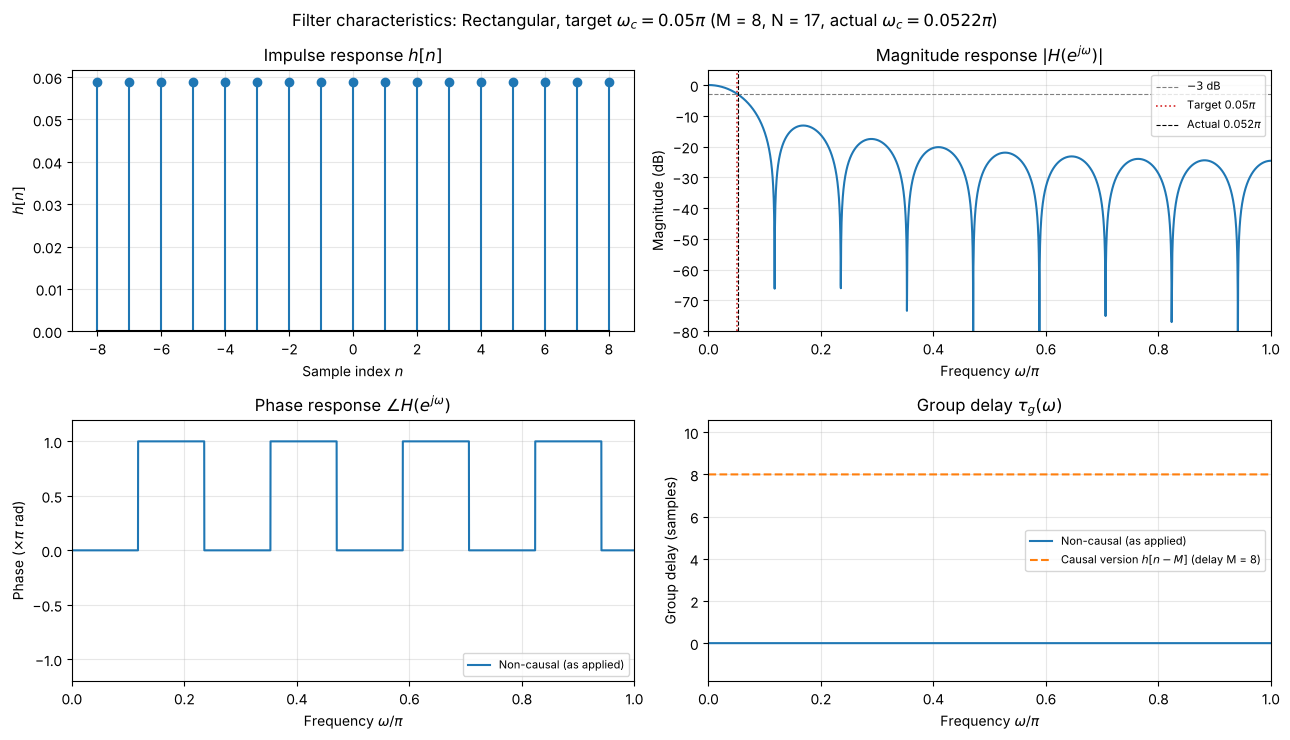

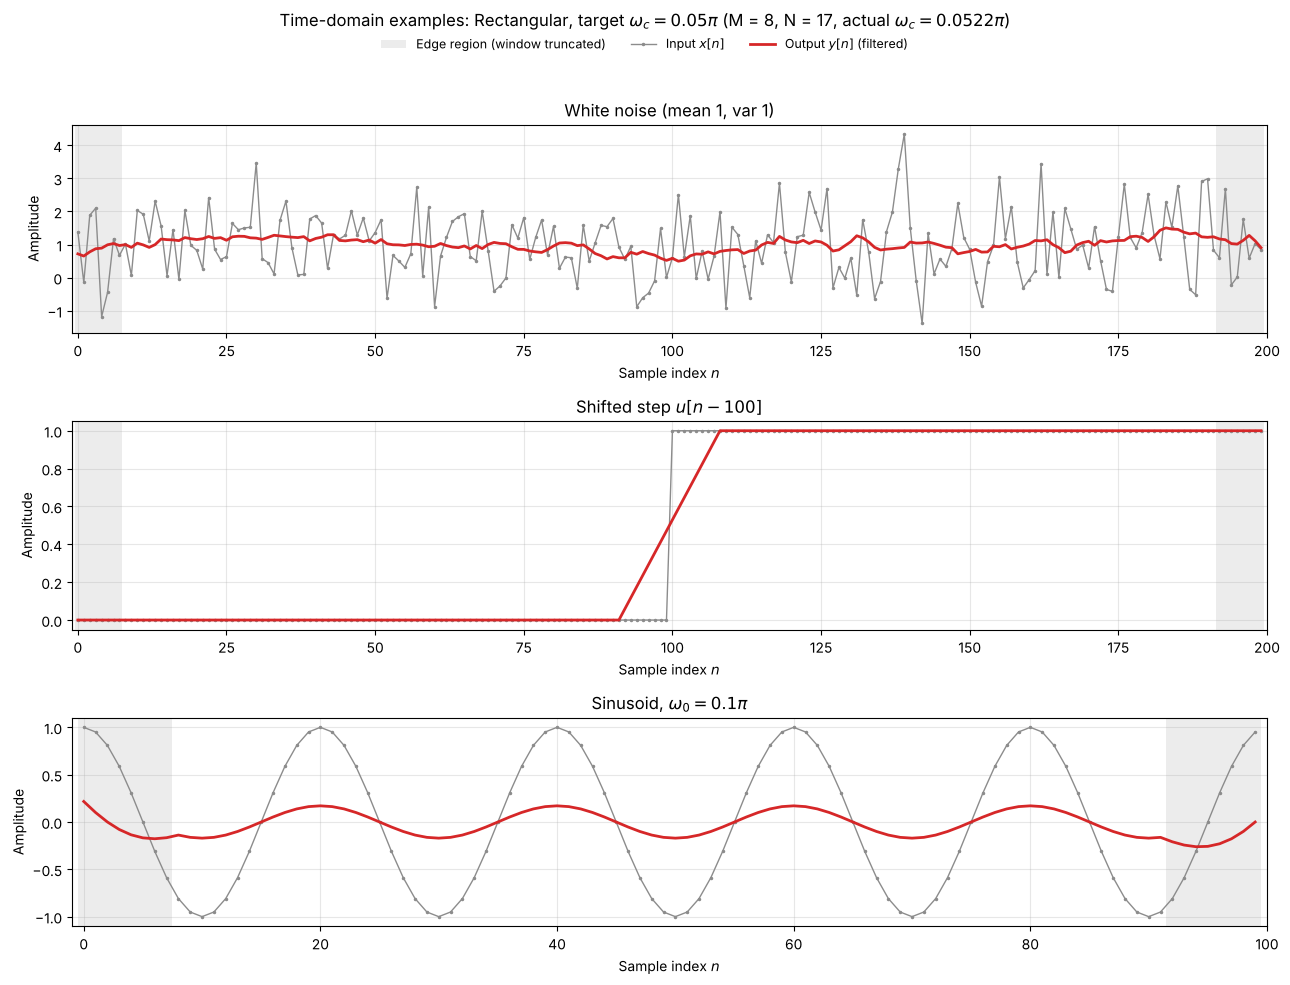

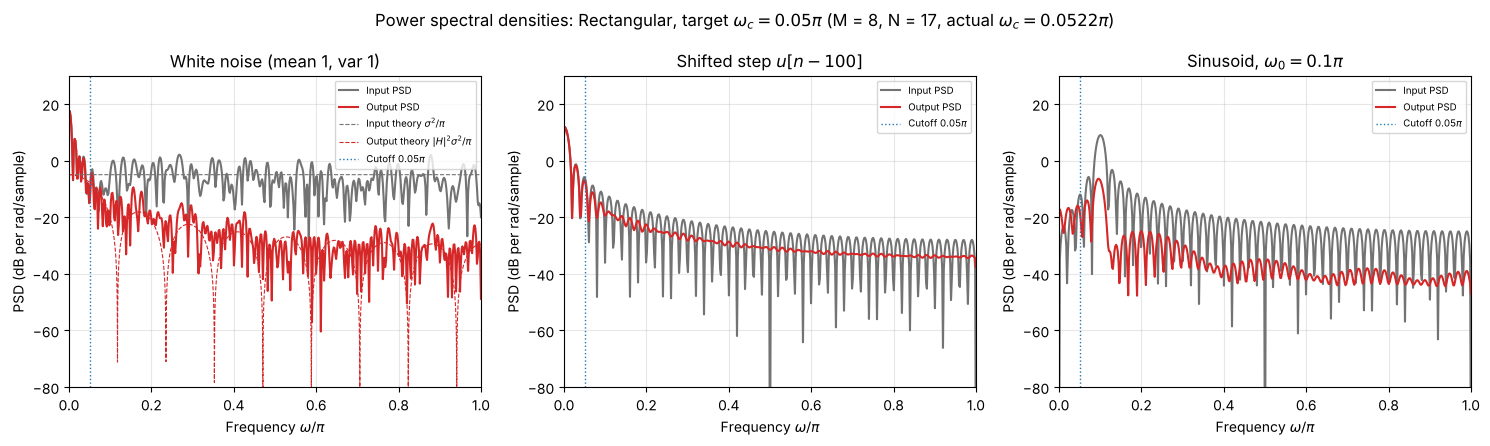

In [12]:
report_design("Rectangular", 0.05)

#### Rectangular, $\omega_c = 0.1\pi$

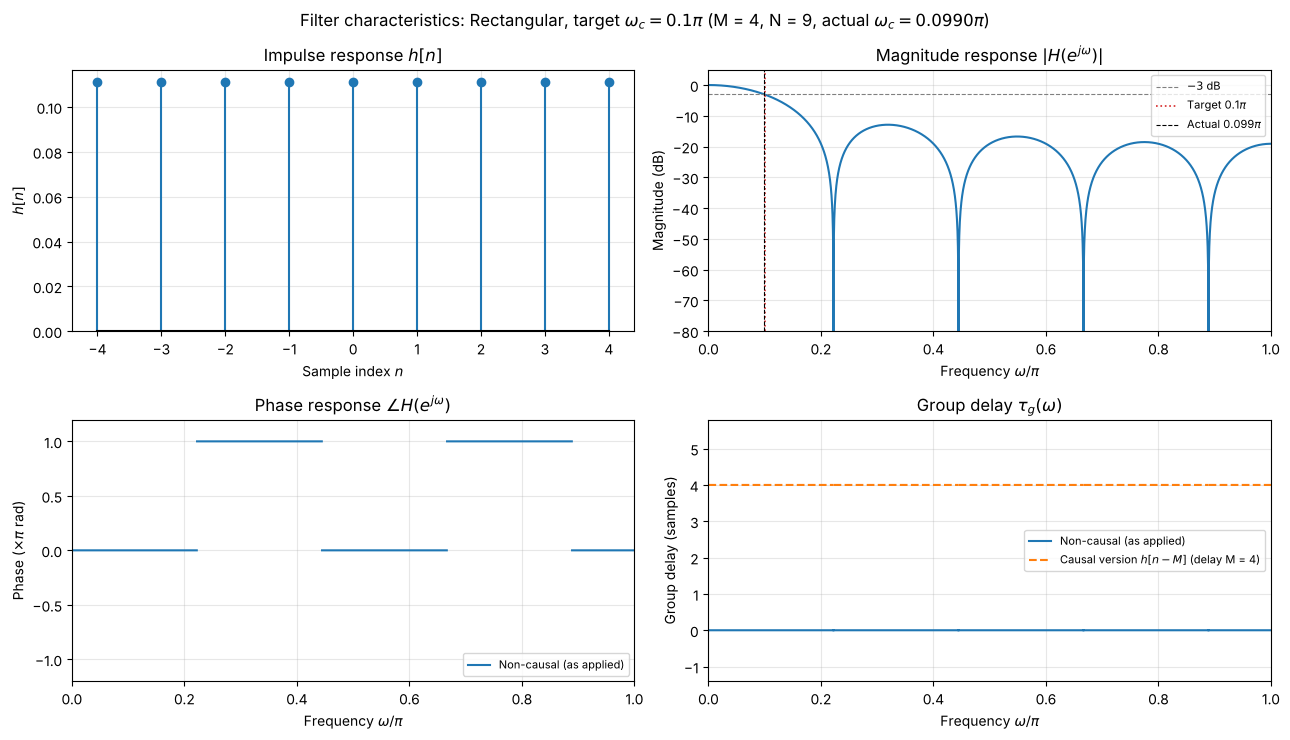

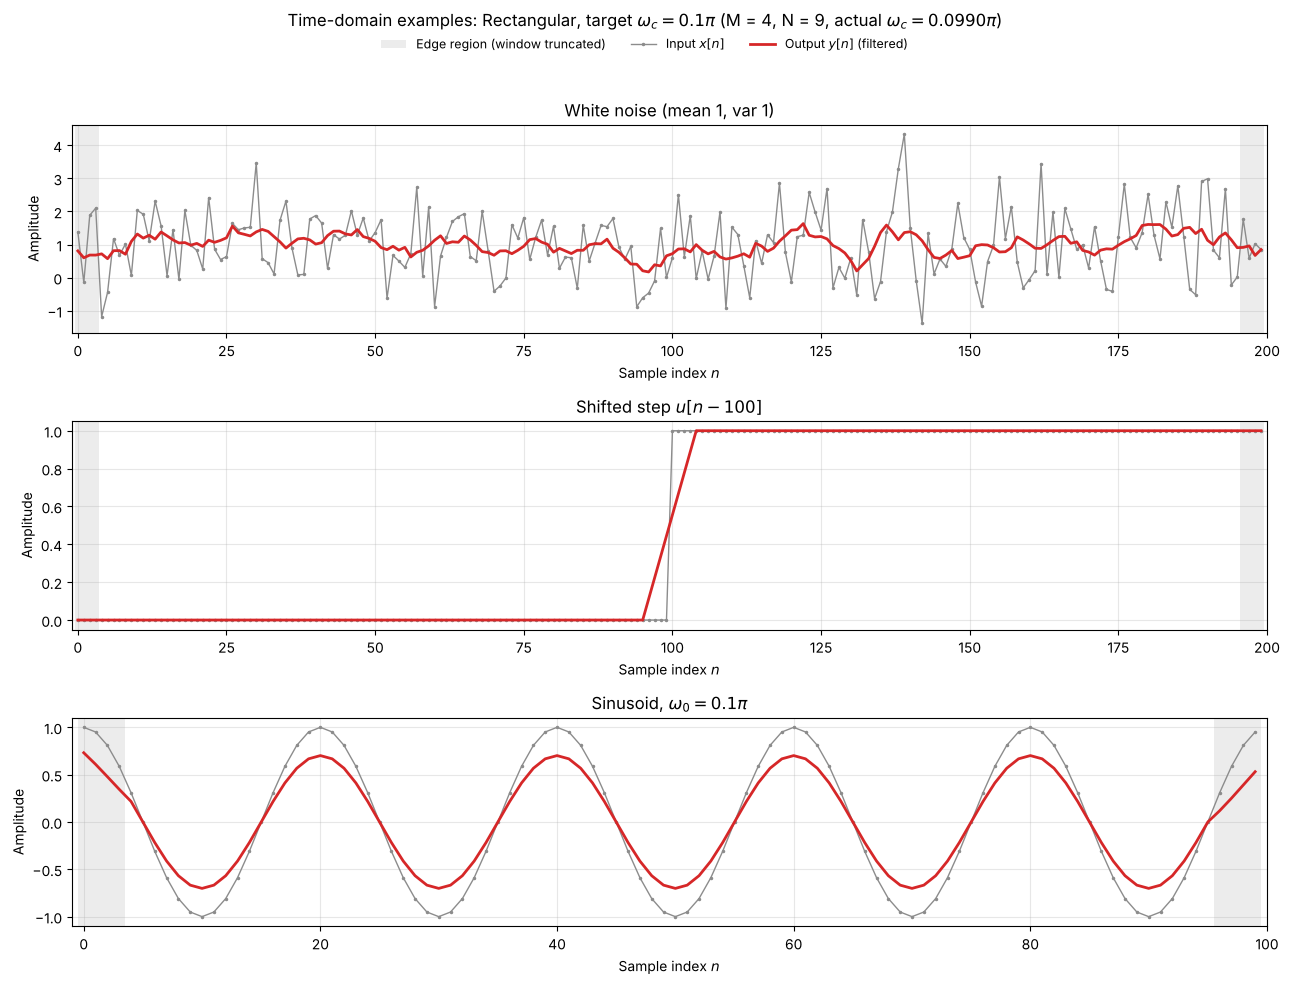

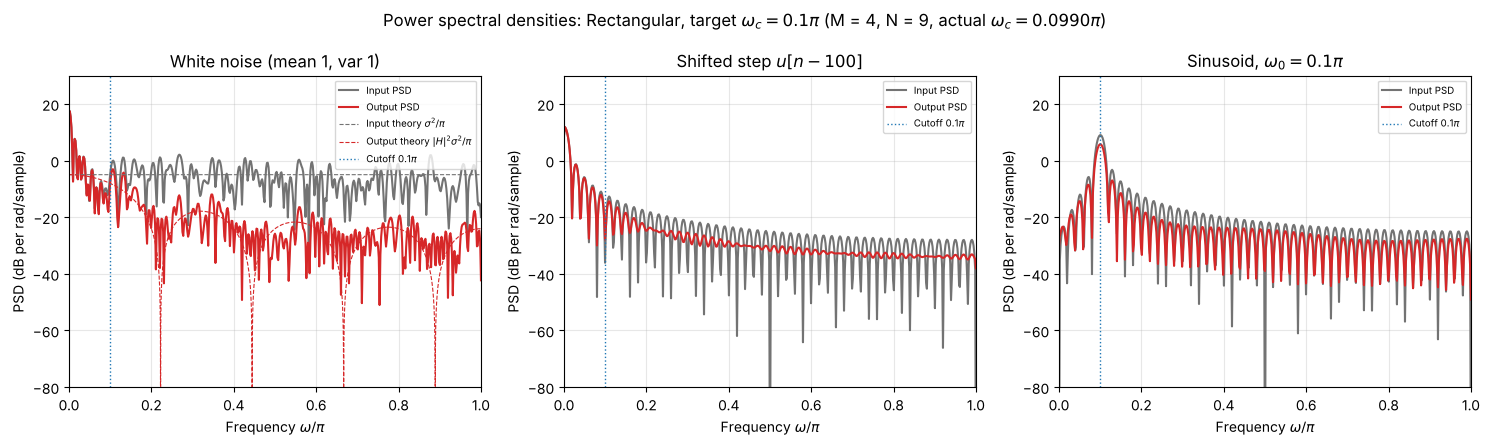

In [13]:
report_design("Rectangular", 0.1)

#### Rectangular, $\omega_c = 0.2\pi$

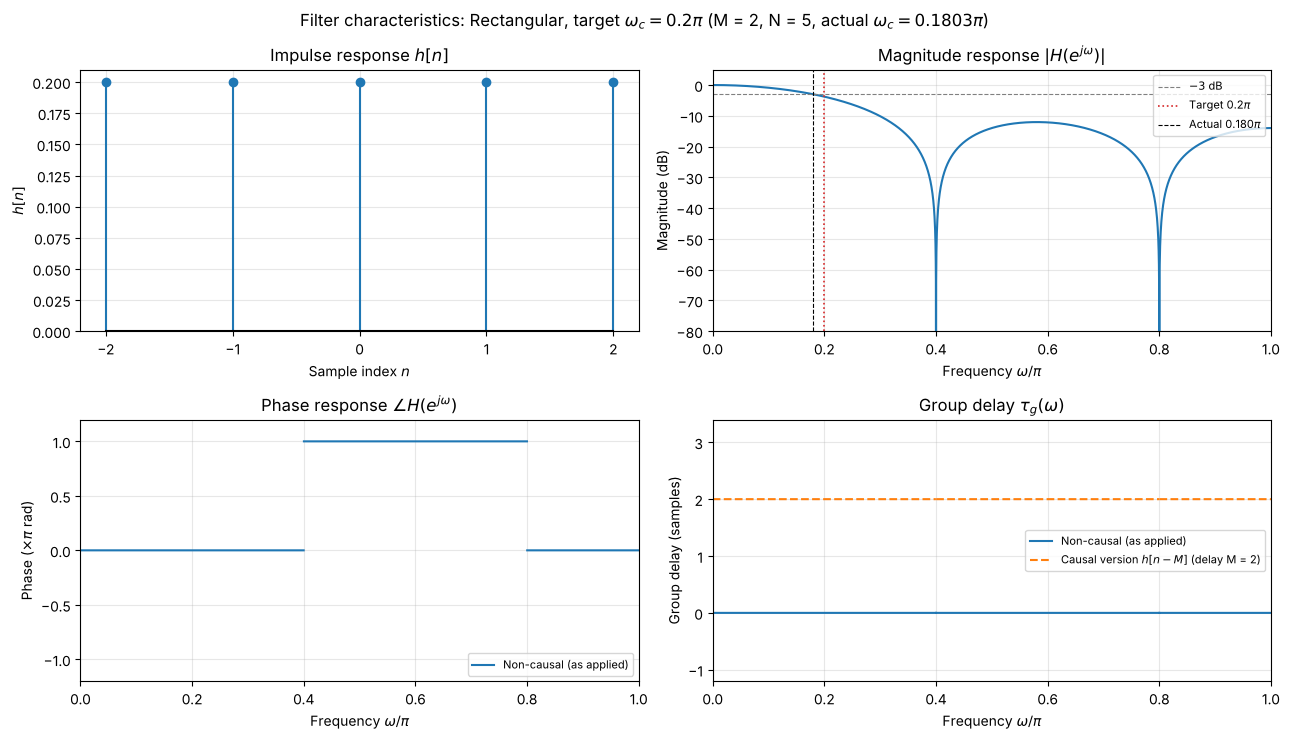

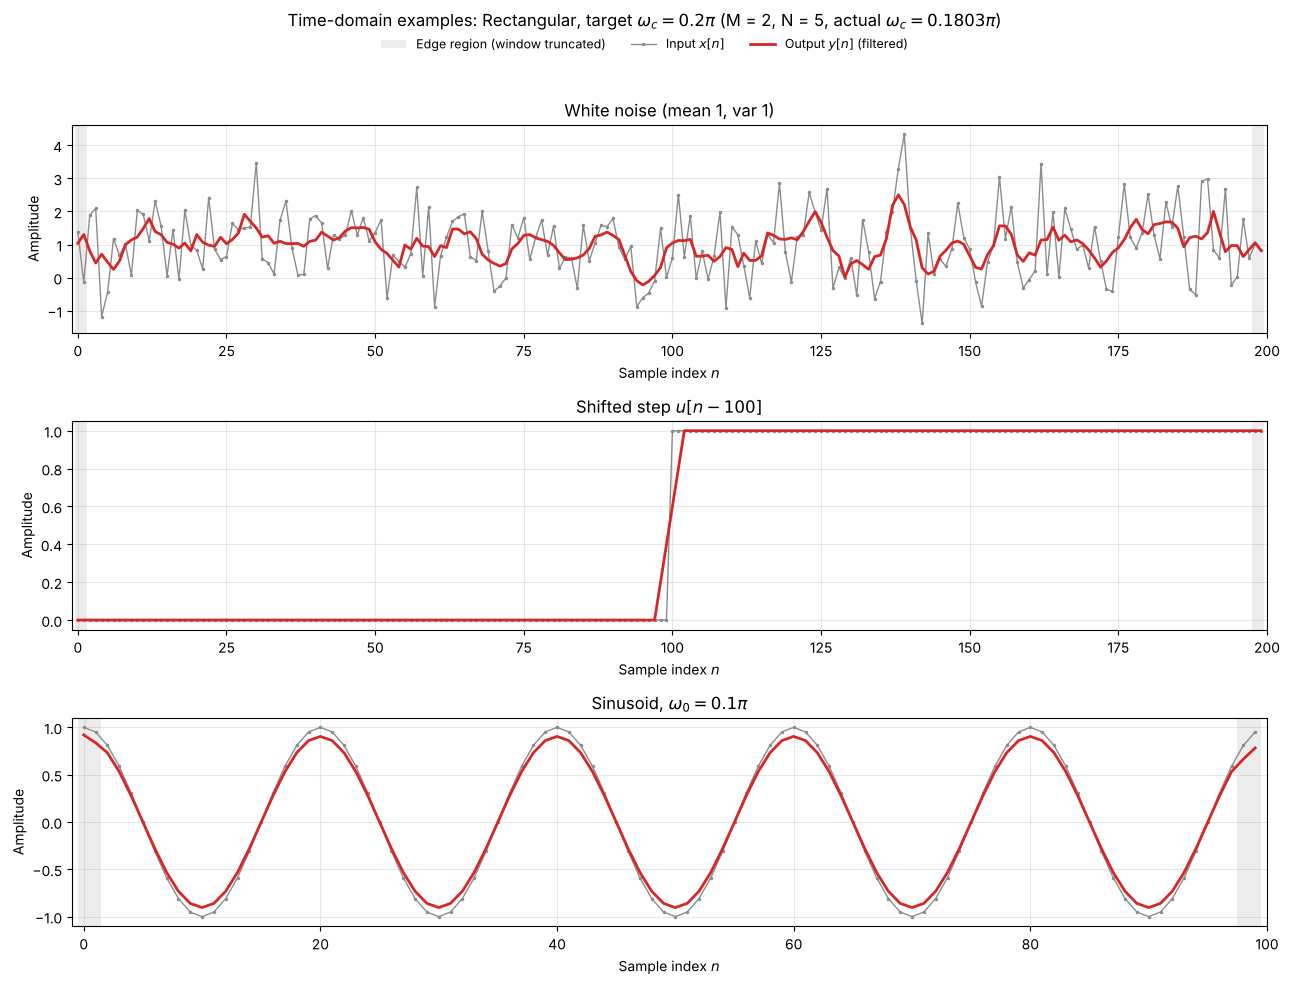

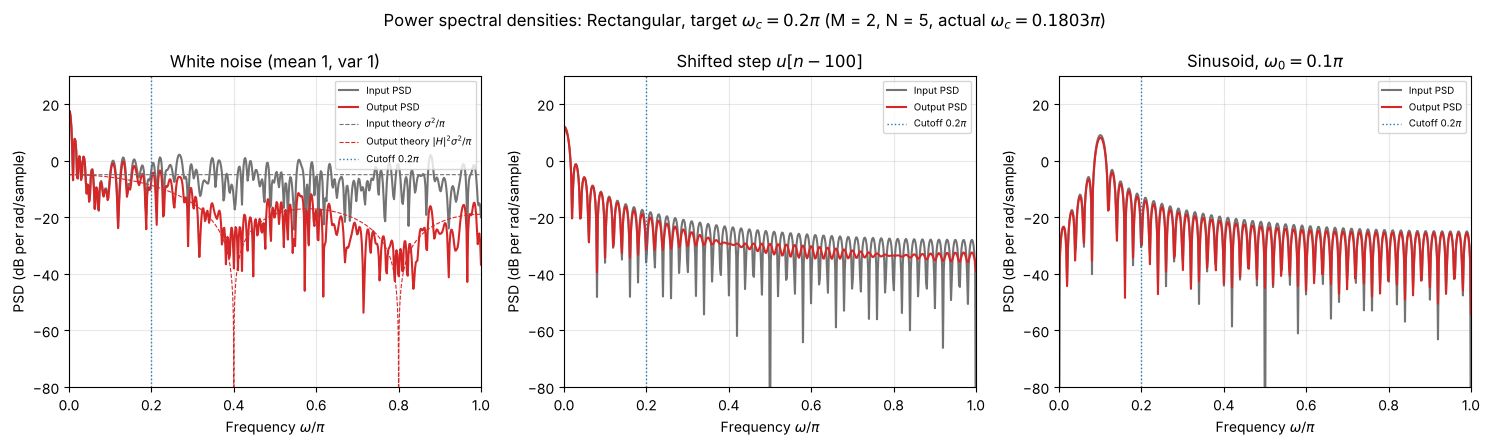

In [14]:
report_design("Rectangular", 0.2)

### Triangular (Bartlett)

#### Triangular, $\omega_c = 0.05\pi$

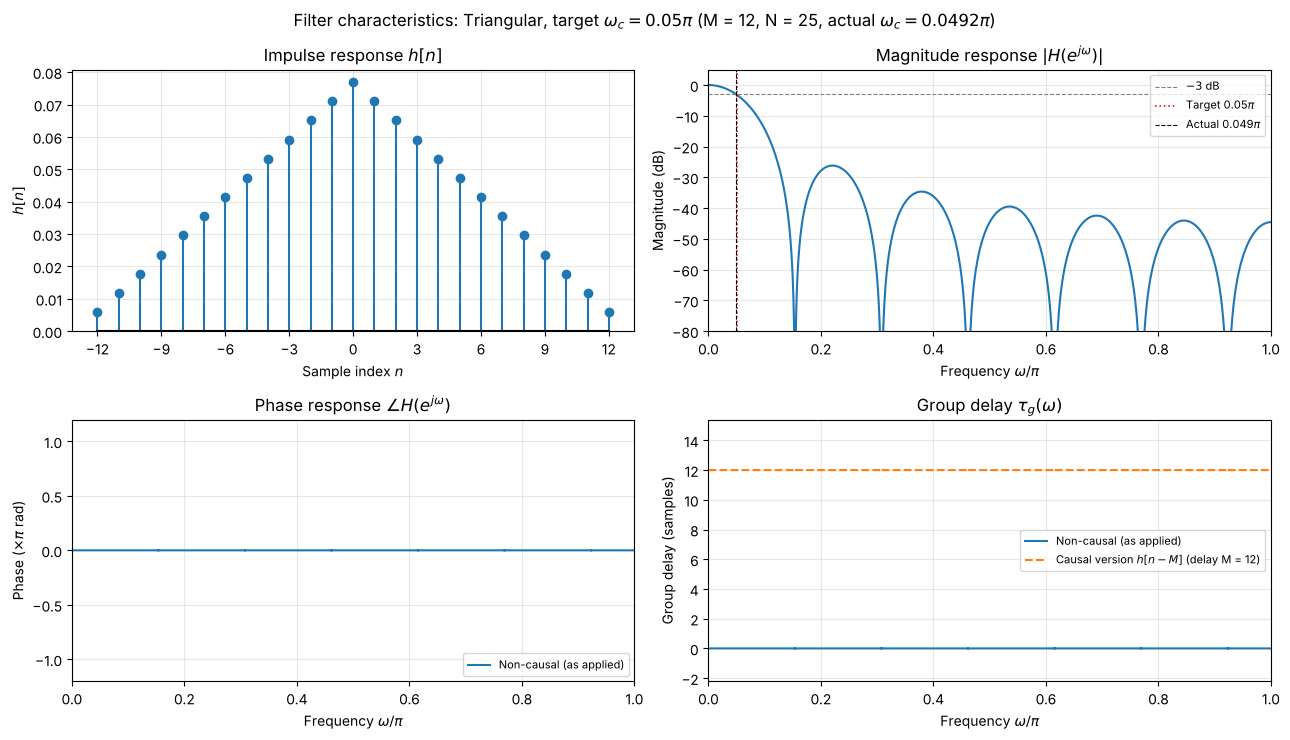

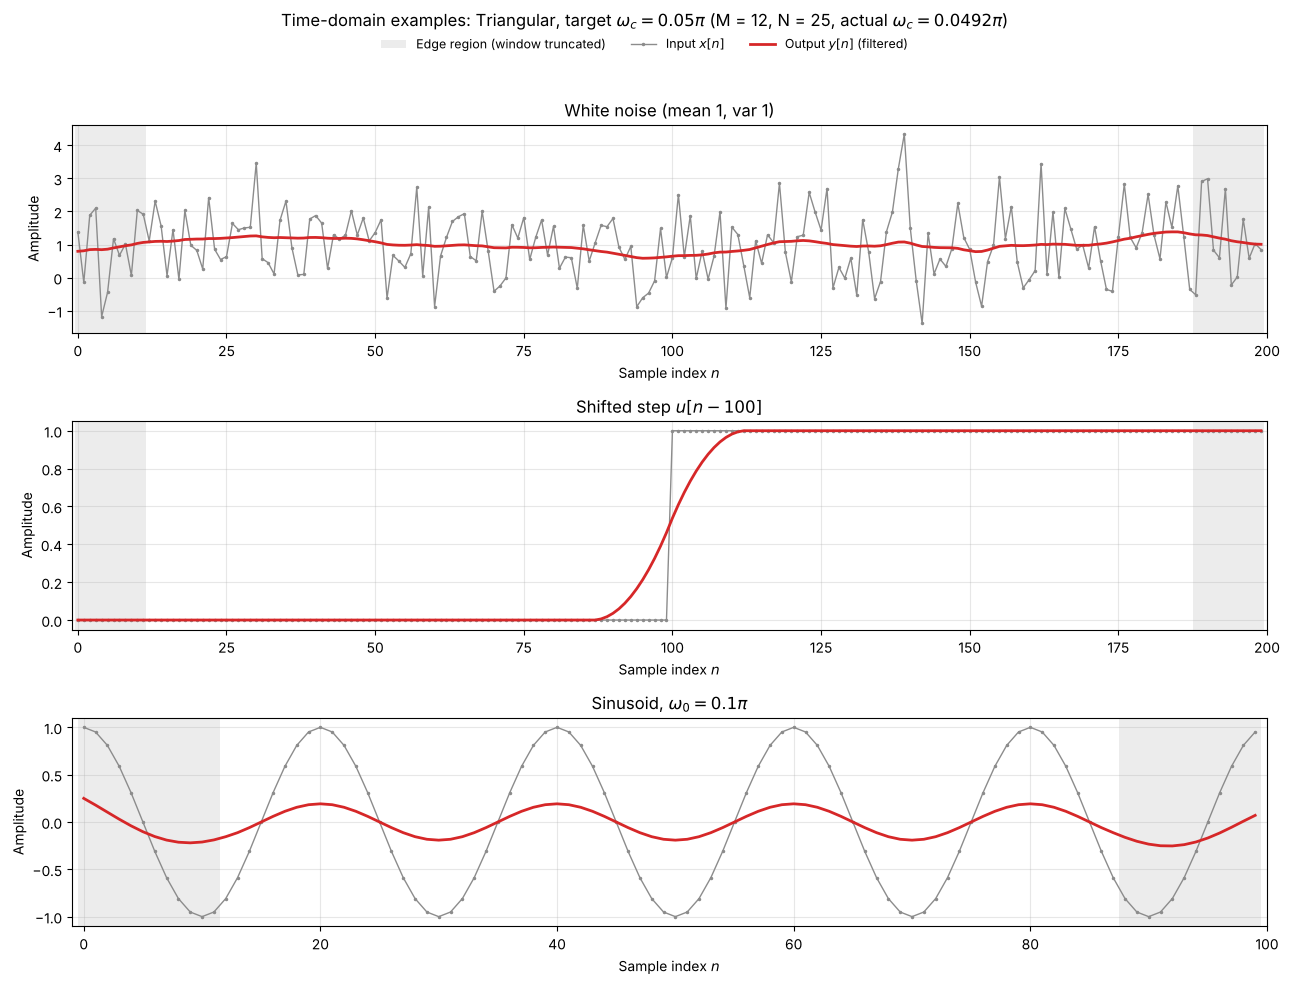

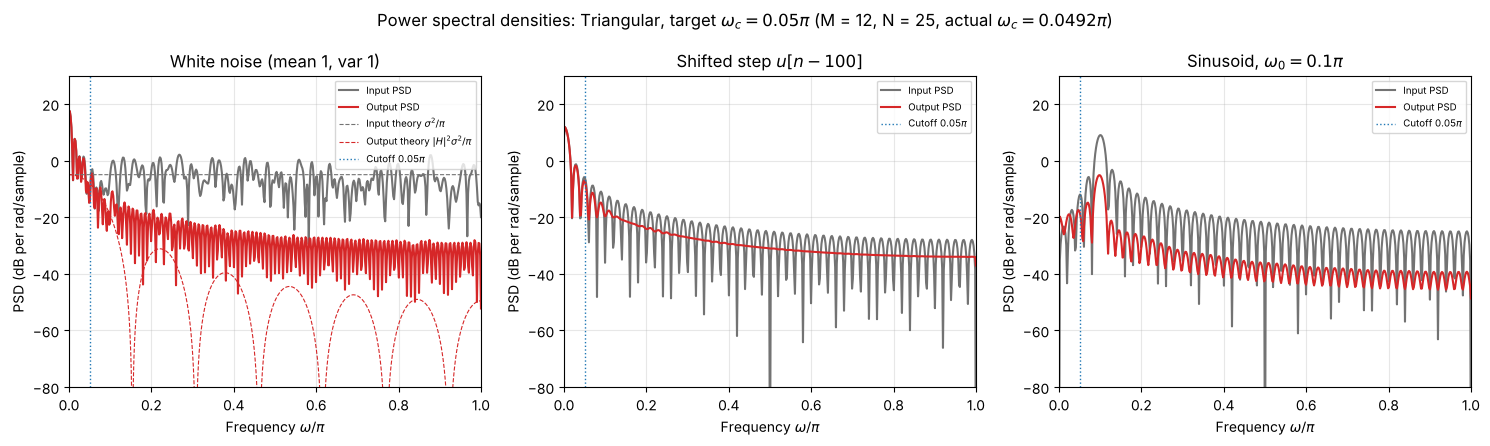

In [15]:
report_design("Triangular", 0.05)

#### Triangular, $\omega_c = 0.1\pi$

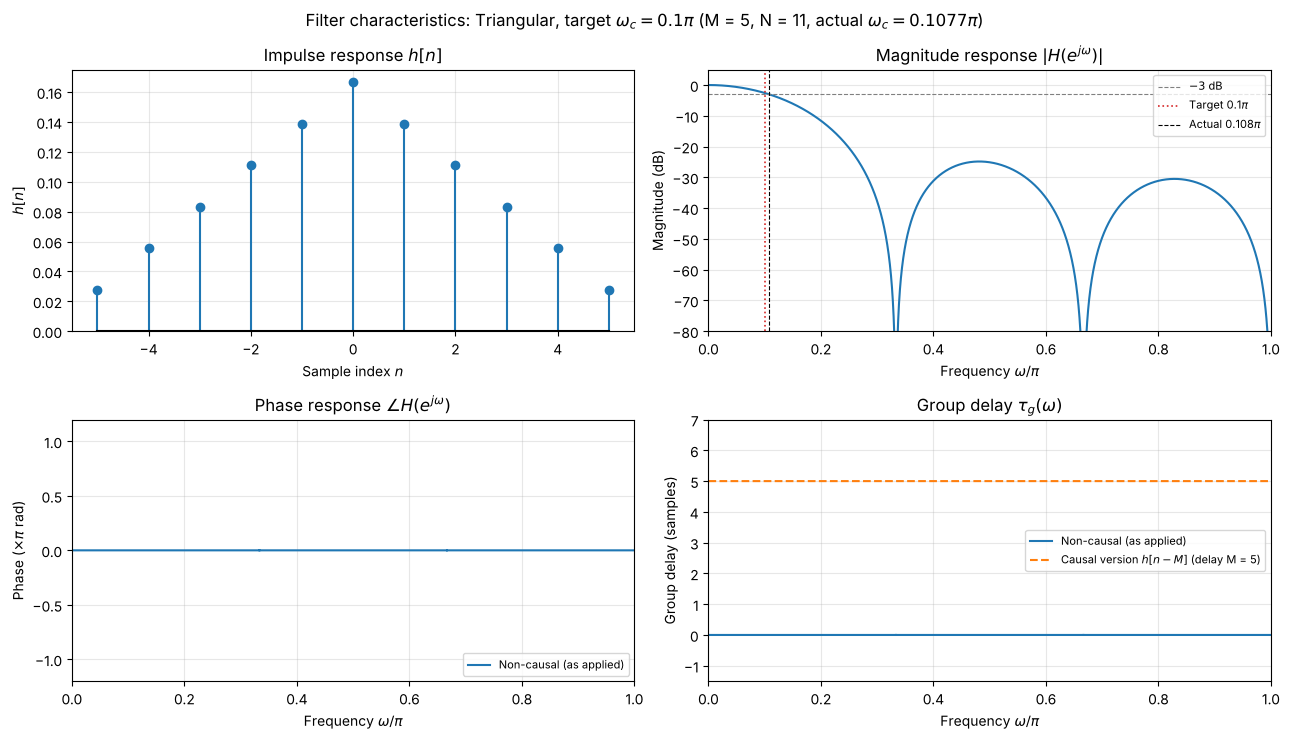

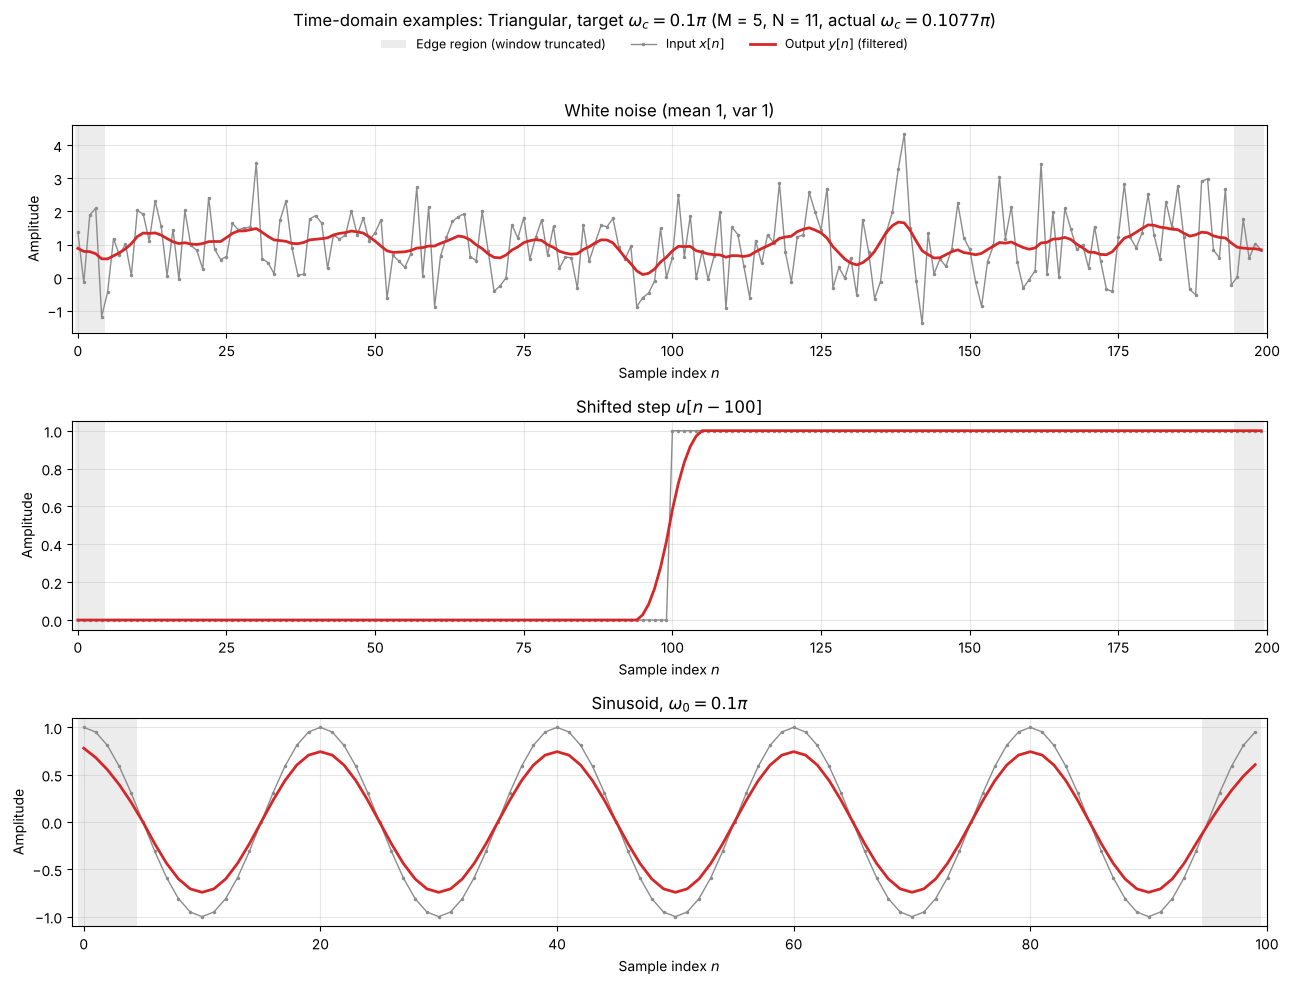

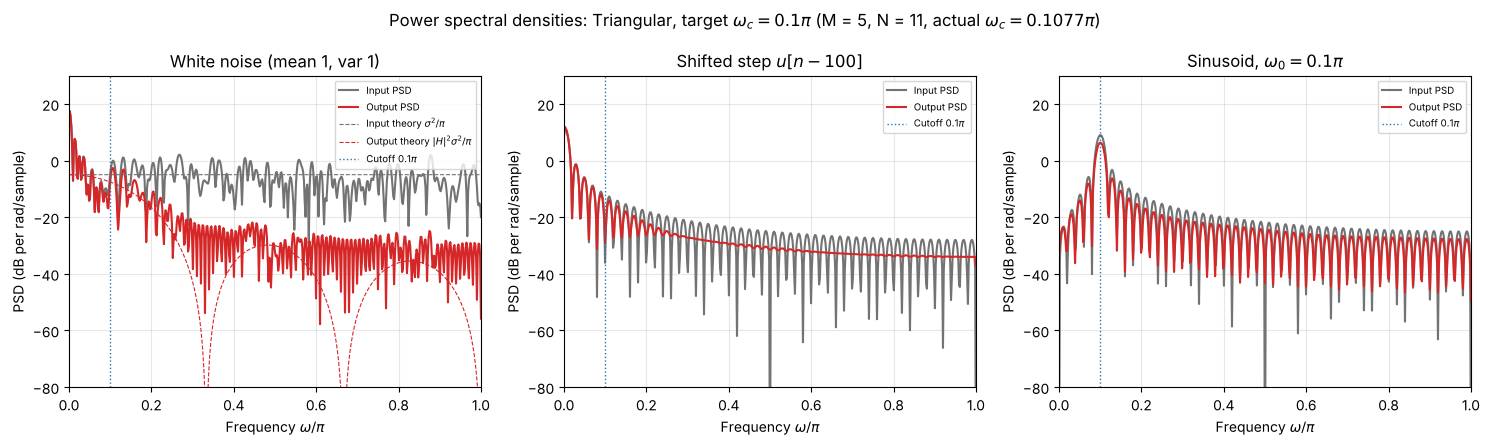

In [16]:
report_design("Triangular", 0.1)

#### Triangular, $\omega_c = 0.2\pi$

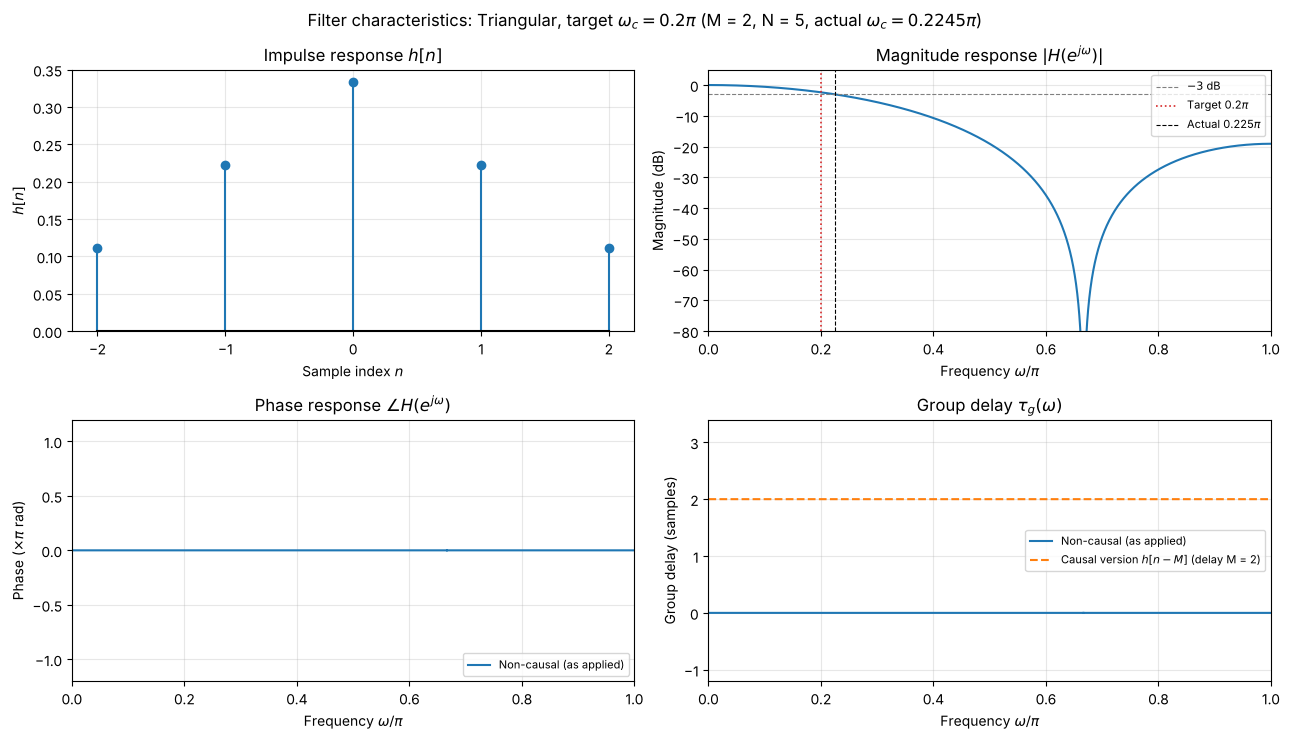

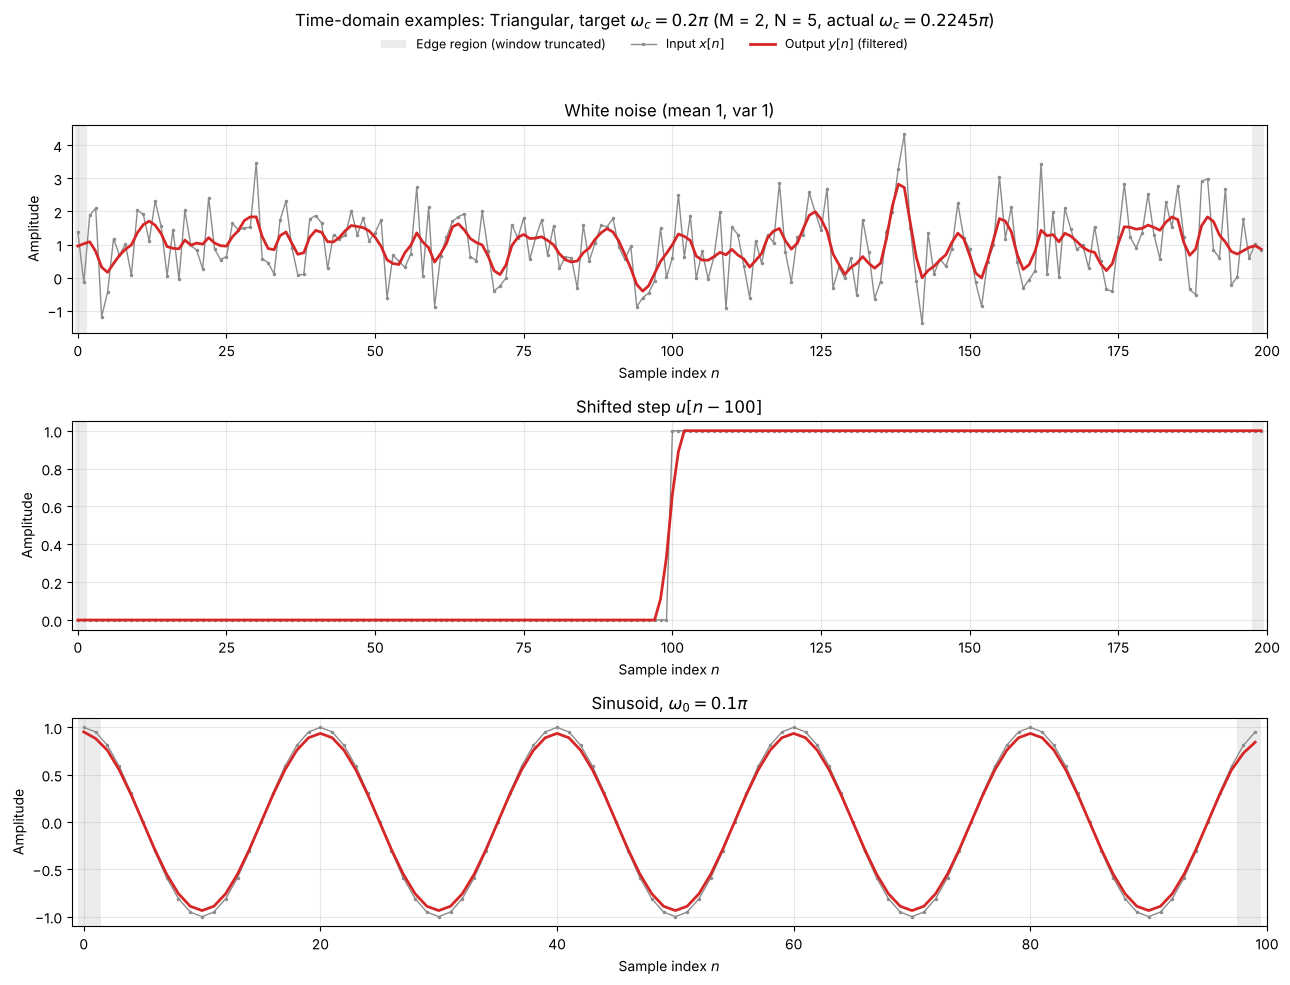

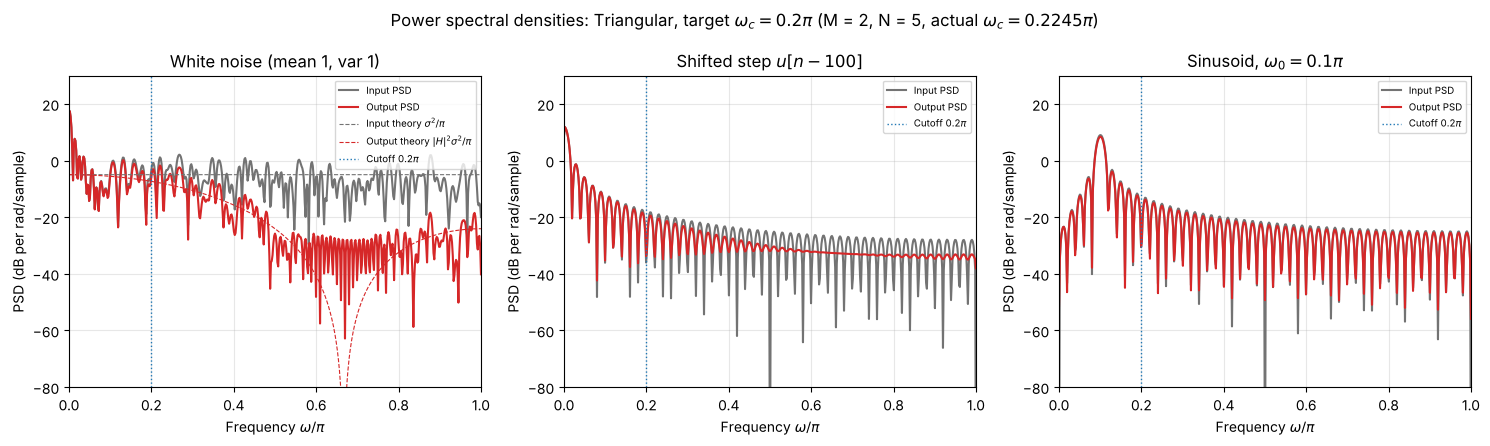

In [17]:
report_design("Triangular", 0.2)

### Binomial

#### Binomial, $\omega_c = 0.05\pi$

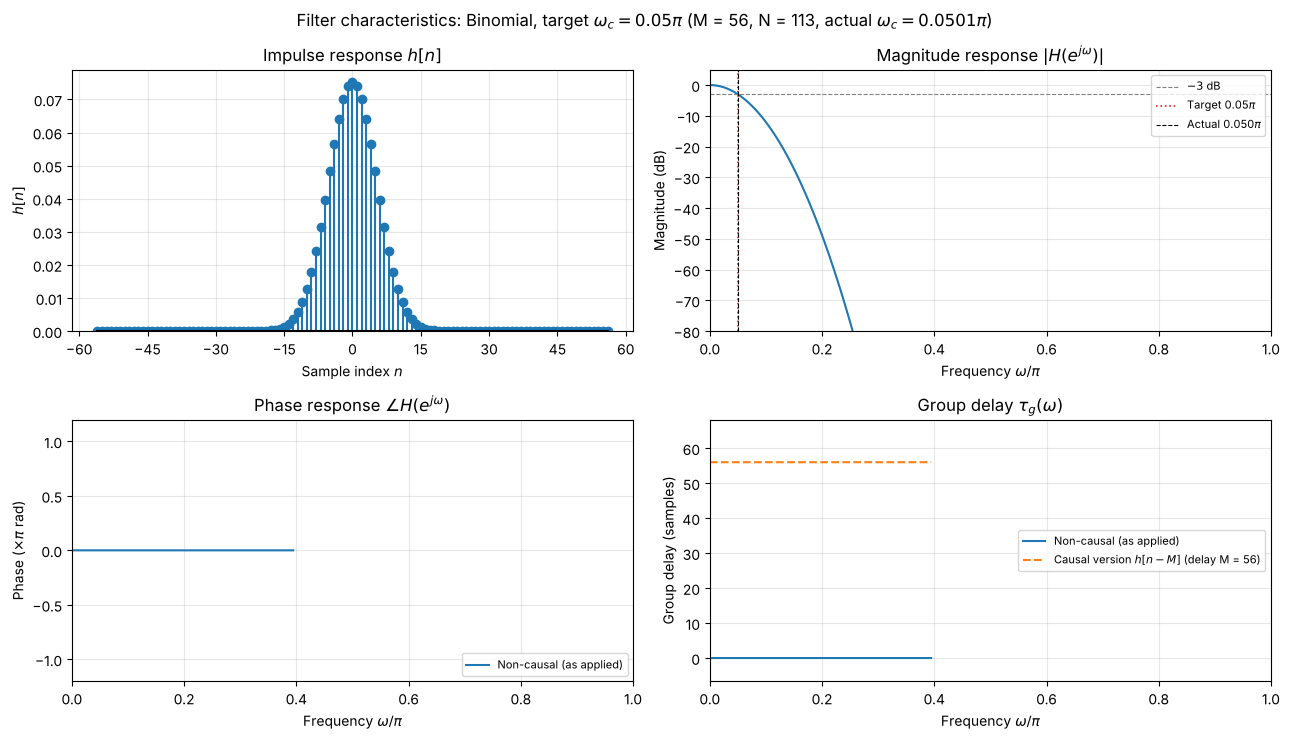

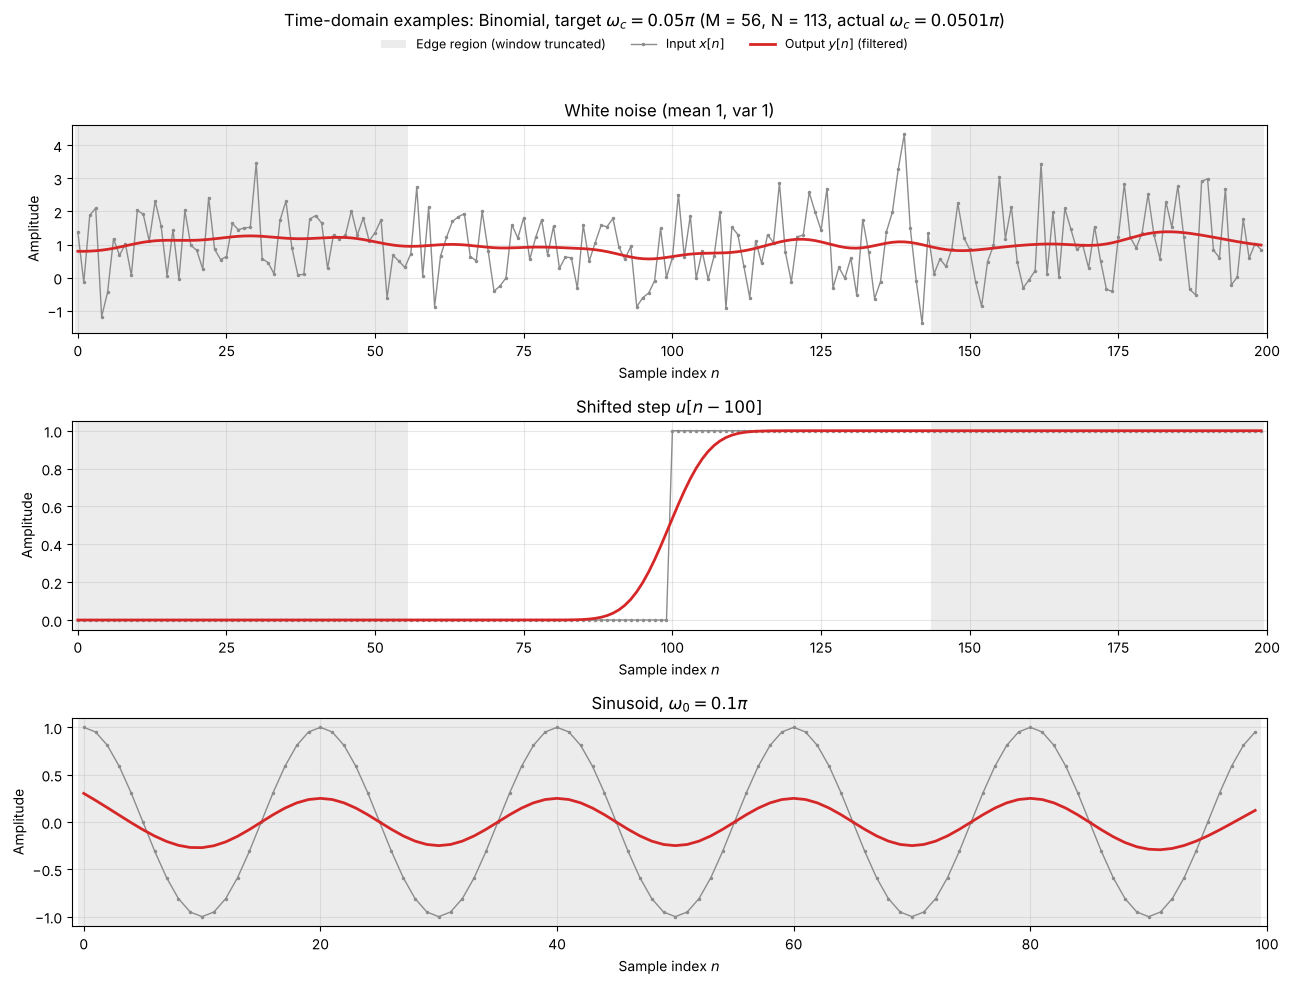

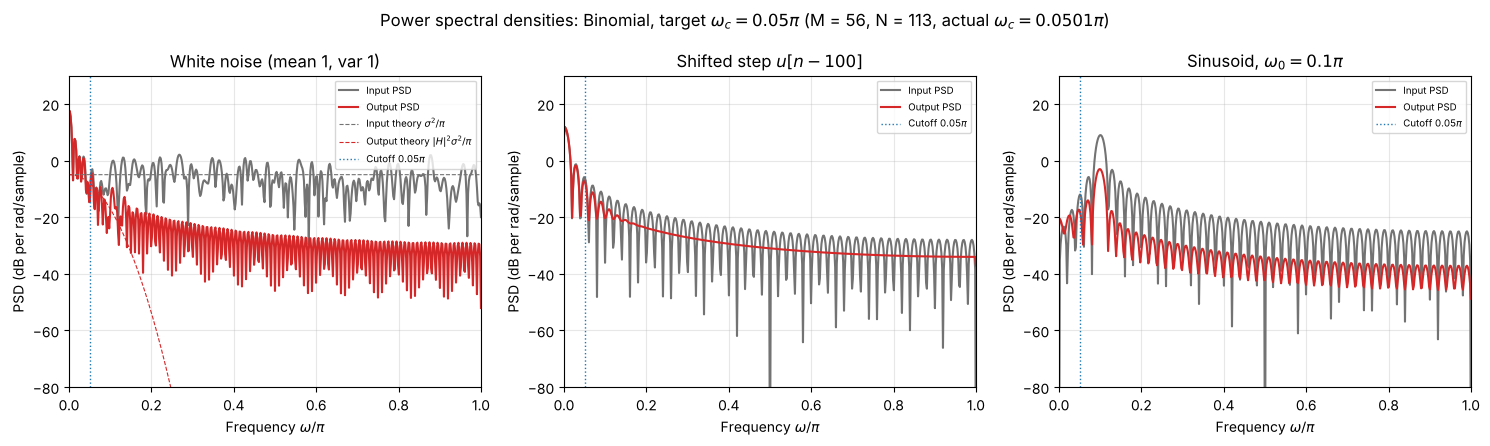

In [18]:
report_design("Binomial", 0.05)

#### Binomial, $\omega_c = 0.1\pi$

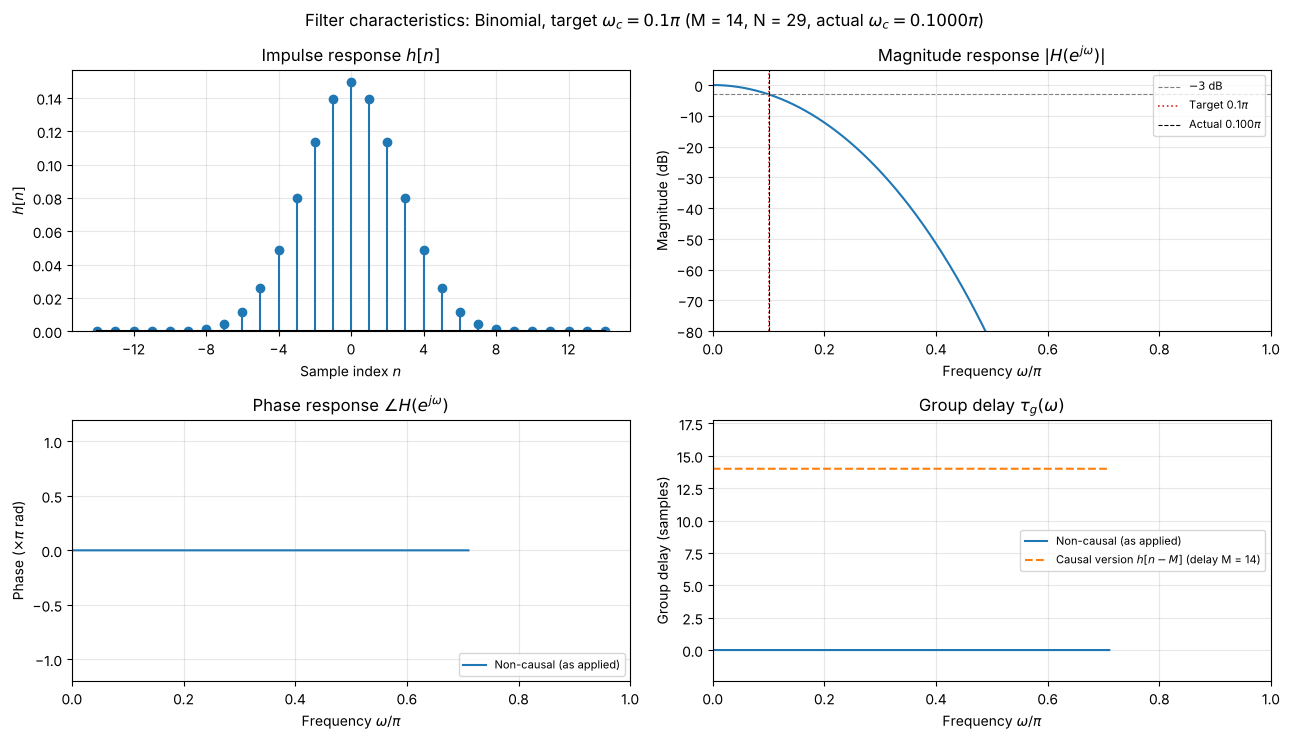

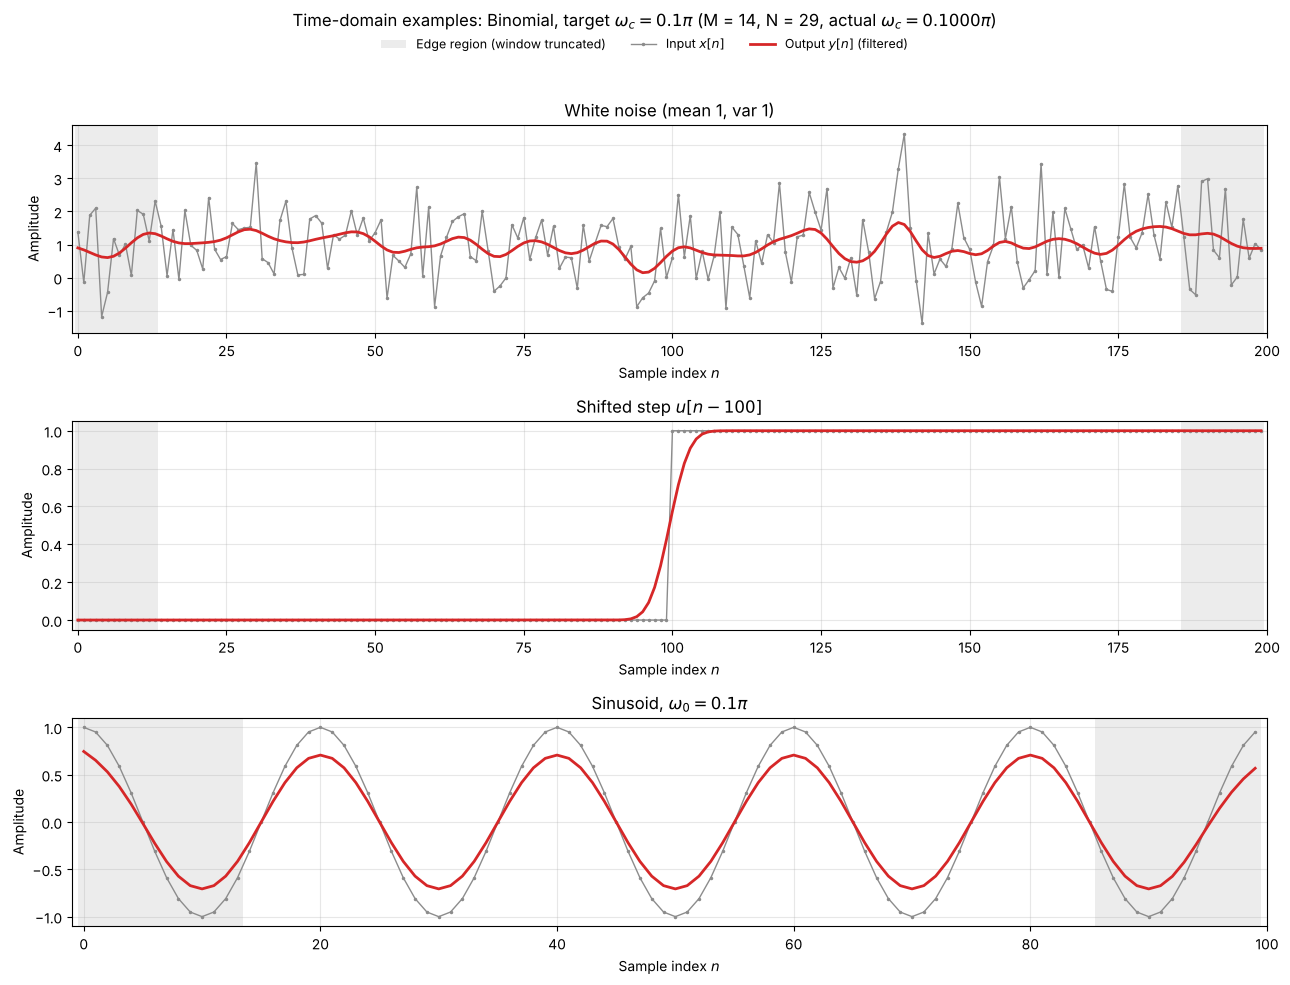

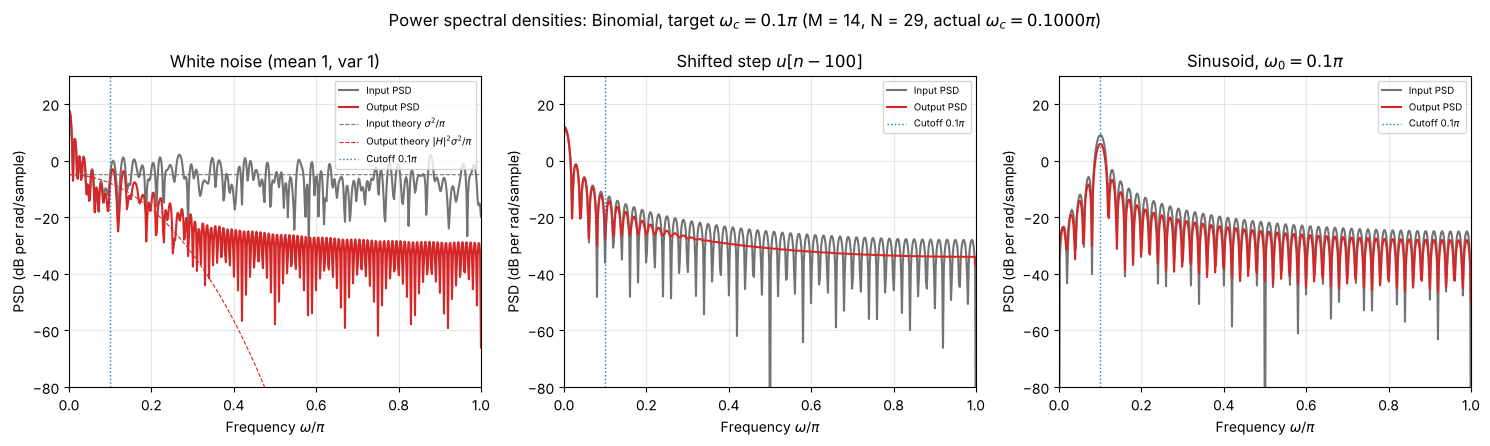

In [19]:
report_design("Binomial", 0.1)

#### Binomial, $\omega_c = 0.2\pi$

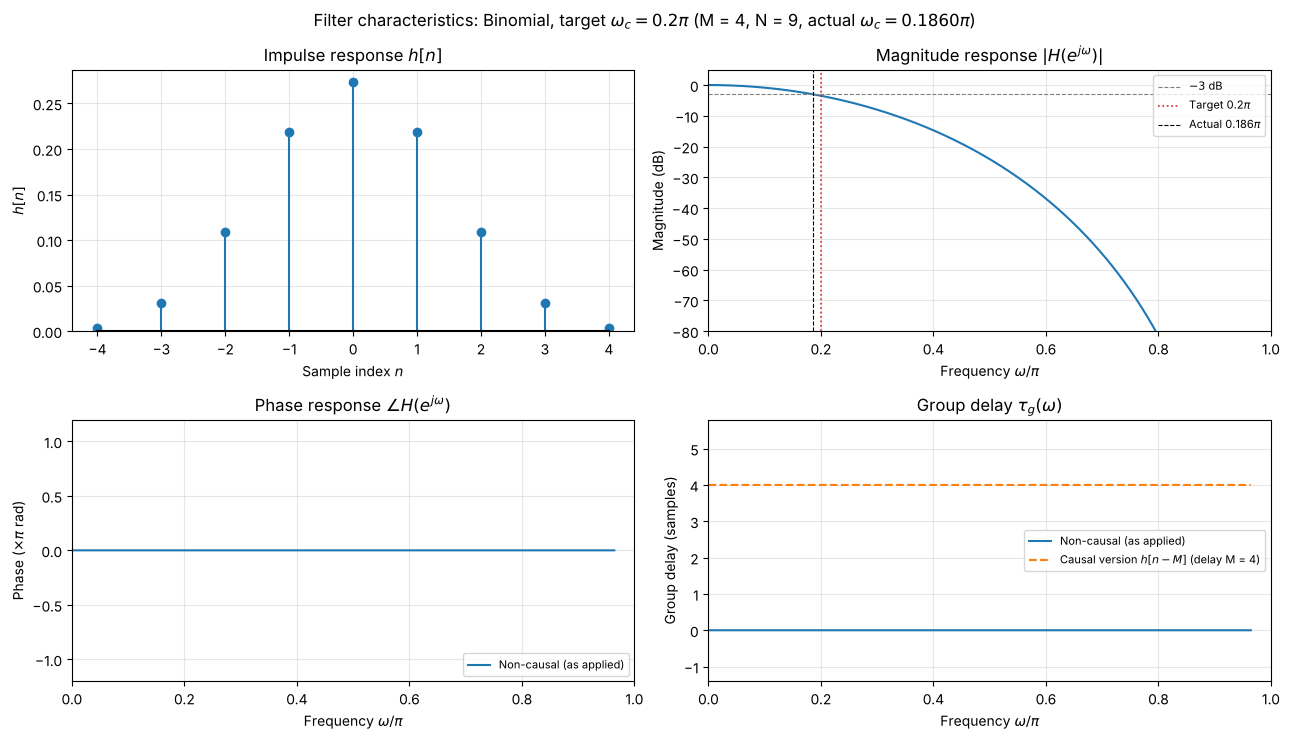

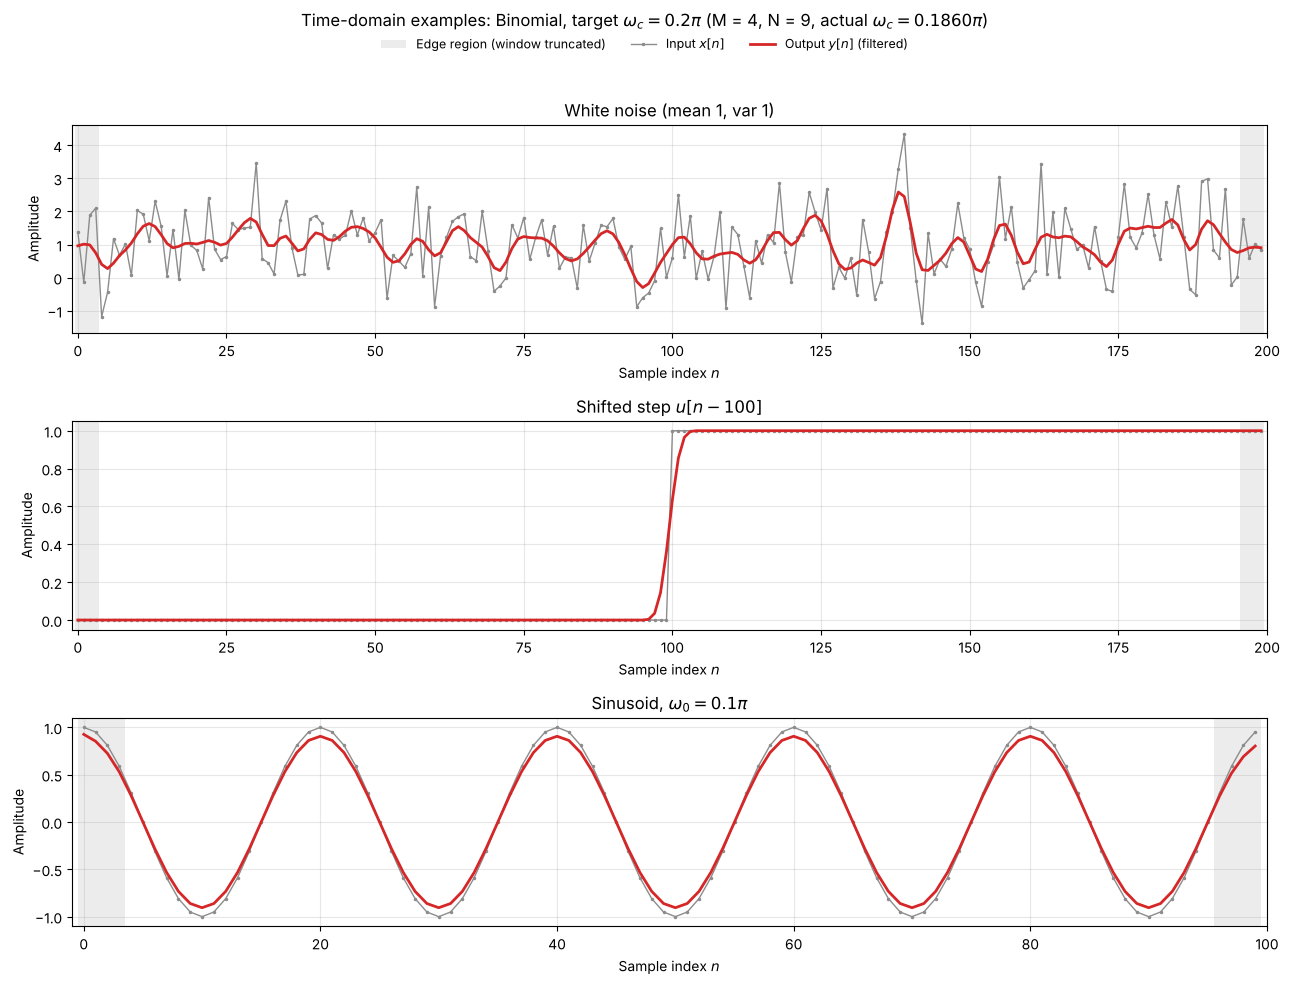

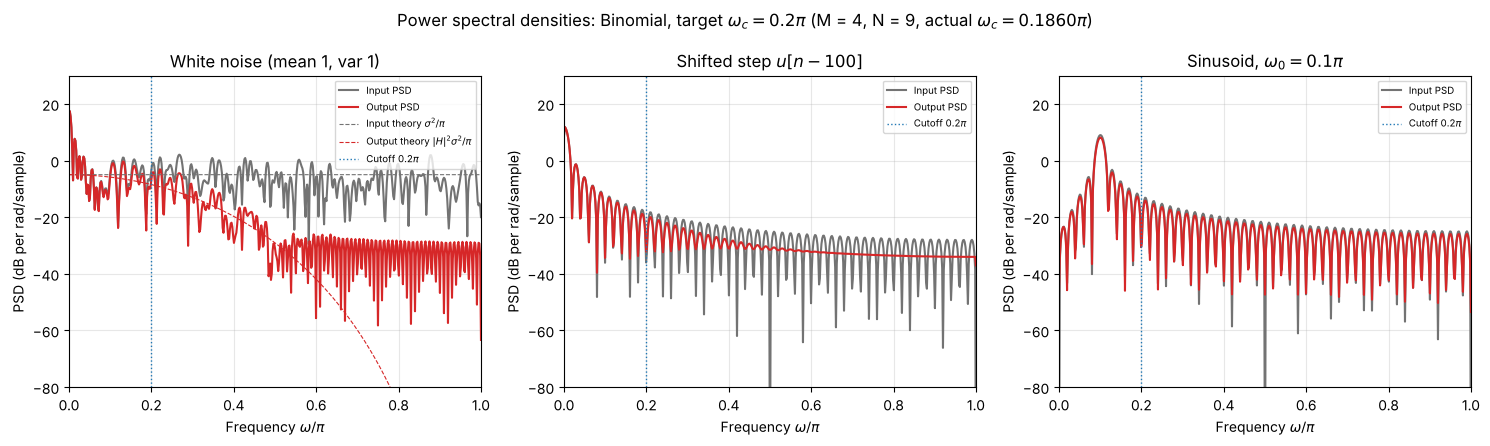

In [20]:
report_design("Binomial", 0.2)

## Problem 3: Explain how this type of filter might be used as a highpass filter. Provide an example with the following:
* Magnitude response
* Phase response
* Group delay
* Impulse response
* Time domain example of the filter applied to a white noise, signal with 200 samples
* Power spectral density plot of the input signal
* Power spectral density plot of the output signal

### Idea: subtract the smoothed signal from the original

A smoothing filter keeps the slowly varying part of a signal (the trend). Subtracting that trend from the original leaves only the fast-varying part. In filter terms, the highpass filter is the **complement** of the lowpass filter:
$$
y_{\text{hp}}[n] = x[n] - (h_{\text{lp}} * x)[n]
\quad\Longleftrightarrow\quad
h_{\text{hp}}[n] = \delta[n] - h_{\text{lp}}[n]
\quad\Longleftrightarrow\quad
H_{\text{hp}}(e^{j\omega}) = 1 - H_{\text{lp}}(e^{j\omega}).
$$

**Properties inherited from the lowpass filter:**

- **Zero DC gain:** $H_{\text{hp}}(e^{j0}) = 1 - \sum_n h_{\text{lp}}[n] = 1 - 1 = 0$. The unit-DC-gain normalization from Problem 1 is exactly what makes the highpass reject DC completely, so any constant offset (such as the mean of 1 in the test noise) is removed.
- **Even symmetry and zero phase:** $\delta[n]$ and $h_{\text{lp}}[n]$ are both even, so $h_{\text{hp}}[n]$ is even and $H_{\text{hp}}(e^{j\omega})$ is real. Because $H_{\text{lp}}(e^{j\omega}) \le 1$ for every non-negative filter (the taps sum to 1, so $|H| \le \sum |h| = 1$), $H_{\text{hp}}(e^{j\omega}) = 1 - H_{\text{lp}}(e^{j\omega}) \ge 0$ at every frequency. The phase is therefore zero wherever $H_{\text{hp}} \ne 0$, and the group delay is zero (or a constant $M$ samples for the causal version).
- **Same length:** $h_{\text{hp}}$ has the same $2M+1$ taps as $h_{\text{lp}}$. Only the center tap changes, to $1 - h_{\text{lp}}[0]$.
- **Not non-negative:** $h_{\text{hp}}[0] = 1 - h_{\text{lp}}[0] > 0$, and every other tap is $-h_{\text{lp}}[n] \le 0$. The taps sum to 0, as a filter with zero DC gain must.

**Cutoff.** For the highpass filter, the $-3$ dB cutoff is the frequency where $H_{\text{hp}}$ *rises* to $1/\sqrt{2}$, which is where the lowpass filter has fallen to $1 - 1/\sqrt{2} \approx 0.293$ ($-10.7$ dB). So a highpass cutoff of $\omega_c$ needs a lowpass filter whose own $-3$ dB cutoff is below $\omega_c$, and therefore a somewhat longer filter.

**Edge handling.** I compute the output as $y_{\text{hp}} = x - \text{apply\_filter}(x, h_{\text{lp}})$, using the same normalized convolution as in Problem 2. Because the lowpass part preserves DC exactly at the edges, the highpass output still rejects DC at the edges, so the output does not jump at the ends of the record. (Zero-padding would make the smoothed trend sag toward 0 at the ends, and the highpass output would then show a spurious jump of about 1 at each end of the mean-1 noise.)

### Choosing the lowpass prototype

For a target highpass cutoff of $\omega_c = 0.1\pi$, I find the length of each Problem 1 filter whose complement comes closest to that cutoff, and compare the three highpass magnitude responses.

Prototype       M    N  HP cutoff  Max gain
Rectangular     7   15    0.1008π    +1.73 dB
Triangular     11   23    0.0957π    +0.00 dB
Binomial       50  101    0.0996π    +0.00 dB


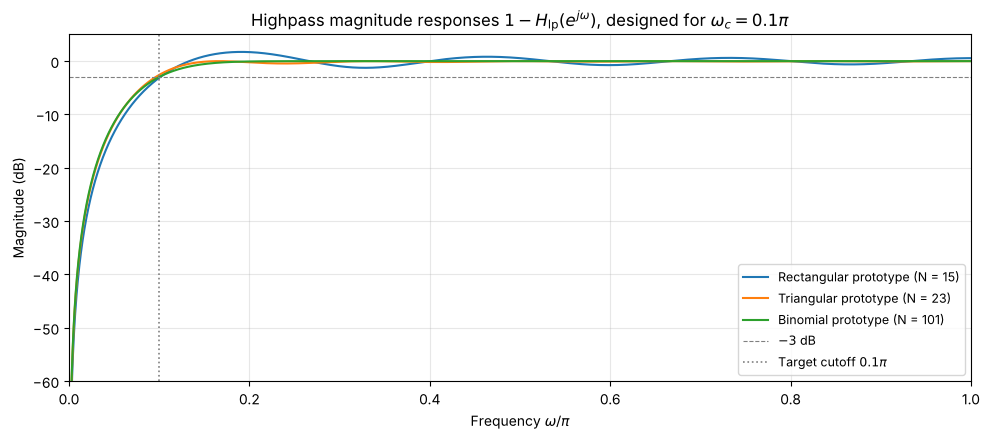

In [21]:
def highpass_from_lowpass(h_lp):
    # h_hp[n] = delta[n] - h_lp[n], with both centered at n = 0
    M = (len(h_lp) - 1) // 2
    h_hp = -h_lp.copy()
    h_hp[M] += 1.0
    return h_hp


def cutoff_3dB_highpass(filter_fn, M, n_grid=8192):
    # First frequency (rad/sample) where 1 - H_lp rises to 1/sqrt(2).
    _, h = filter_fn(M)
    level = 1 / np.sqrt(2)
    w = np.linspace(0, np.pi, n_grid)
    Hhp = 1 - amplitude_response(h, M, w)
    i = np.argmax(Hhp >= level)
    f = lambda x: 1 - amplitude_response(h, M, np.array([x]))[0] - level
    return brentq(f, w[i - 1], w[i])


hp_target = 0.1 * np.pi
hp_design = {}
for name, fn in filters.items():
    wcs = np.array([cutoff_3dB_highpass(fn, M) for M in M_range])
    i = np.argmin(np.abs(wcs - hp_target))
    hp_design[name] = (M_range[i], wcs[i])

fig, ax = plt.subplots(figsize=(10, 4.5))
print(f"{'Prototype':12s} {'M':>4s} {'N':>4s} {'HP cutoff':>10s} {'Max gain':>9s}")
for name, fn in filters.items():
    M, wc = hp_design[name]
    _, h = fn(M)
    Hhp = 1 - amplitude_response(h, M, w_grid)
    print(f"{name:12s} {M:4d} {2*M+1:4d} {wc/np.pi:9.4f}π {20*np.log10(Hhp.max()):+8.2f} dB")
    ax.plot(w_grid / np.pi, 20 * np.log10(np.maximum(Hhp, 1e-6)), color=colors[name],
            label=f"{name} prototype (N = {2*M+1})")
ax.axhline(-3, color="gray", ls="--", lw=0.8, label="$-3$ dB")
ax.axvline(0.1, color="gray", ls=":", lw=1.2, label="Target cutoff $0.1\\pi$")
ax.set_title("Highpass magnitude responses $1 - H_{\\mathrm{lp}}(e^{j\\omega})$, designed for $\\omega_c = 0.1\\pi$")
ax.set_xlabel("Frequency $\\omega/\\pi$")
ax.set_ylabel("Magnitude (dB)")
ax.set_xlim(0, 1)
ax.set_ylim(-60, 5)
ax.grid(True, alpha=0.3)
ax.legend(fontsize=9, loc="lower right")
plt.tight_layout()
plt.show()

**Choice: triangular prototype.** The three complements behave differently above the cutoff:

- **Rectangular:** its lowpass sidelobes go negative, so $1 - H_{\text{lp}}$ rises *above* 1. The passband ripples, amplifying some frequencies by up to about $+1.7$ dB.
- **Triangular:** $H_{\text{lp}}(e^{j\omega}) \ge 0$ (a squared Dirichlet kernel), so $0 \le H_{\text{hp}} \le 1$. The passband never exceeds unity gain, ripple is small, and the filter is short.
- **Binomial:** the cleanest response (monotonic, no ripple at all), but its gradual roll-off means it needs about $4\times$ as many taps for the same cutoff. That makes the edge regions half of a 200-sample record.

The triangular prototype is the best balance of passband flatness and length here, so I use it for the detailed example below.

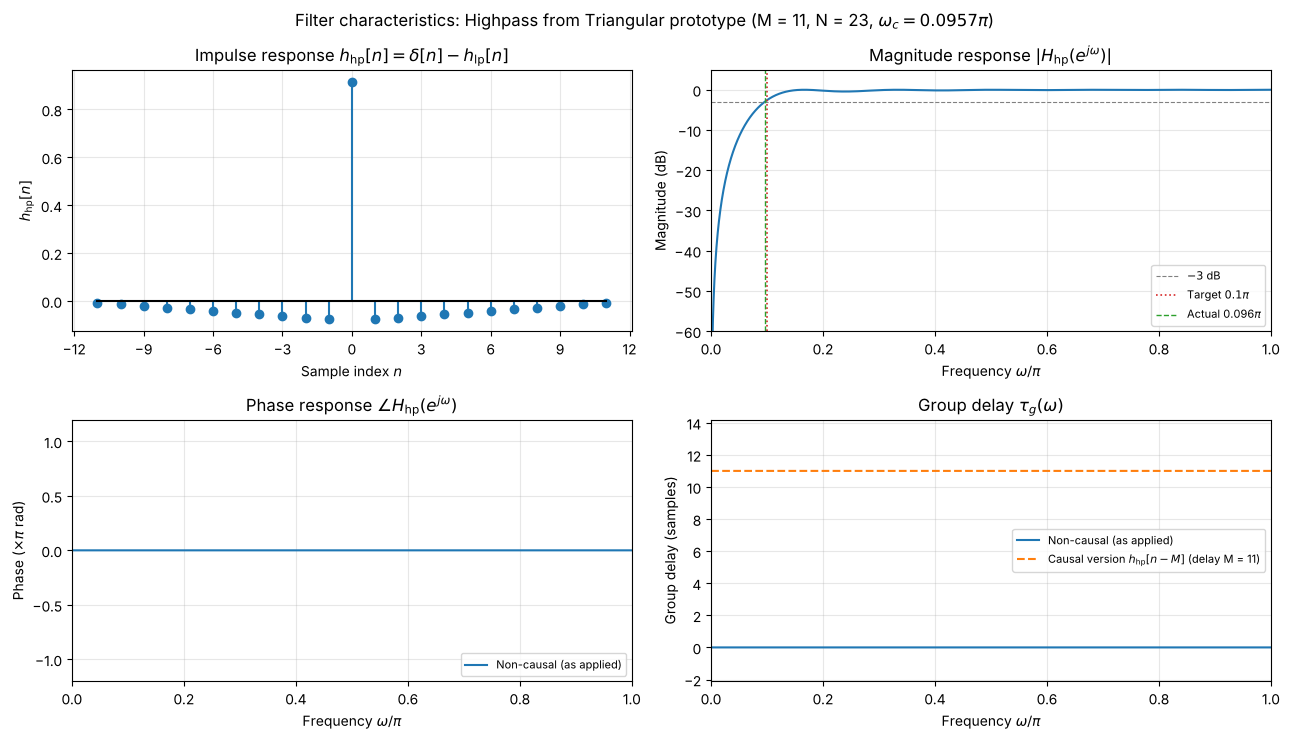

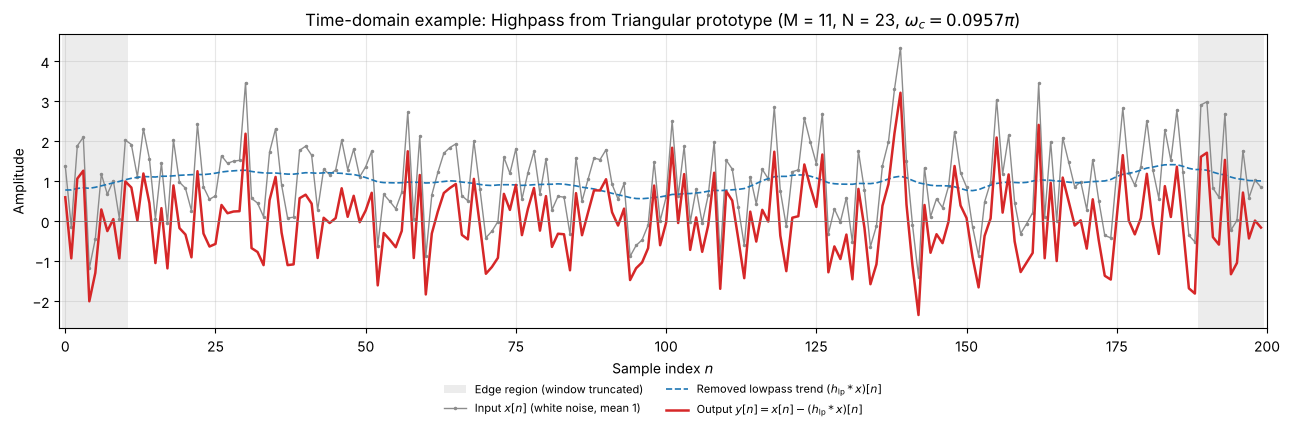

Input : mean = +1.000, variance = 1.000
Output: mean = -0.001, variance = 0.918 (theory for white input: input variance x sum(h_hp^2) = 0.889)


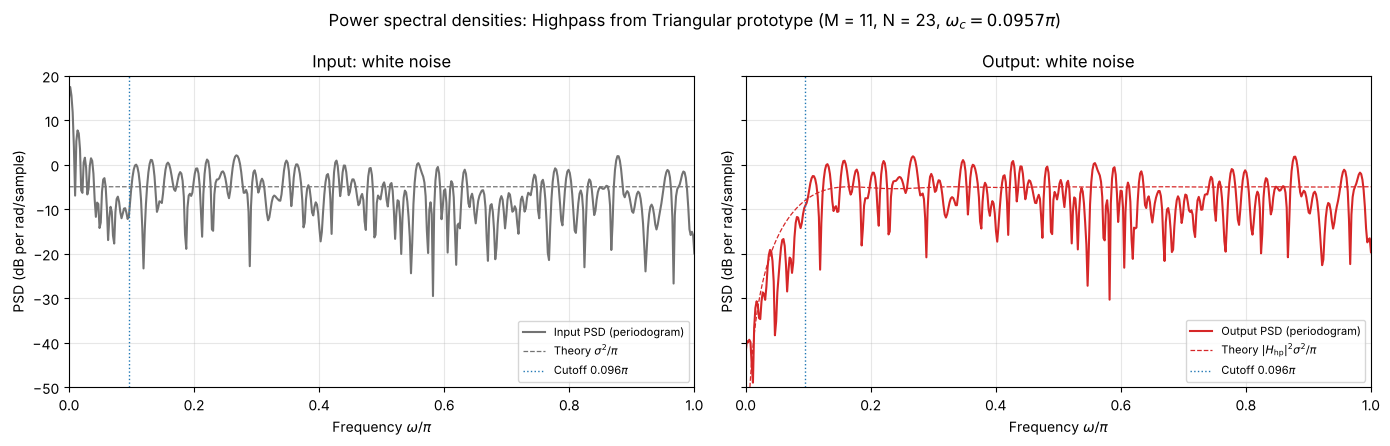

In [22]:
def report_highpass(name):
    fn = filters[name]
    M, wc = hp_design[name]
    n, h_lp = fn(M)
    h_hp = highpass_from_lowpass(h_lp)
    tag = (f"Highpass from {name} prototype (M = {M}, N = {2*M+1}, "
           f"$\\omega_c = {wc/np.pi:.4f}\\pi$)")

    # ---------- Figure 1: filter characteristics ----------
    Hhp = 1 - amplitude_response(h_lp, M, w_grid)           # real (zero-phase) response
    mag_db = 20 * np.log10(np.maximum(np.abs(Hhp), 1e-6))
    tiny = np.abs(Hhp) < 1e-10                              # phase undefined where H = 0
    phase = np.where(Hhp < 0, np.pi, 0.0)
    phase[tiny] = np.nan
    with warnings.catch_warnings(), np.errstate(all="ignore"):
        warnings.simplefilter("ignore")
        _, gd_causal = group_delay((h_hp, [1.0]), w=w_grid)
    gd_causal[np.abs(Hhp) < 1e-6] = np.nan                  # unreliable near the DC null
    gd_noncausal = gd_causal - M

    fig, ax = plt.subplots(2, 2, figsize=(13, 7.5))
    fig.suptitle(f"Filter characteristics: {tag}", fontsize=12)

    a = ax[0, 0]
    a.stem(n, h_hp, basefmt="k-")
    a.set_title("Impulse response $h_{\\mathrm{hp}}[n] = \\delta[n] - h_{\\mathrm{lp}}[n]$")
    a.set_xlabel("Sample index $n$")
    a.set_ylabel("$h_{\\mathrm{hp}}[n]$")
    a.xaxis.set_major_locator(MaxNLocator(integer=True))

    a = ax[0, 1]
    a.plot(w_grid / np.pi, mag_db, color="C0")
    a.axhline(-3, color="gray", ls="--", lw=0.8, label="$-3$ dB")
    a.axvline(0.1, color="C3", ls=":", lw=1.2, label="Target $0.1\\pi$")
    a.axvline(wc / np.pi, color="C2", ls="--", lw=1.0, label=f"Actual {wc/np.pi:.3f}$\\pi$")
    a.set_title("Magnitude response $|H_{\\mathrm{hp}}(e^{j\\omega})|$")
    a.set_xlabel("Frequency $\\omega/\\pi$")
    a.set_ylabel("Magnitude (dB)")
    a.set_ylim(-60, 5)
    a.legend(fontsize=8, loc="lower right")

    a = ax[1, 0]
    a.plot(w_grid / np.pi, phase / np.pi, color="C0", label="Non-causal (as applied)")
    a.set_title("Phase response $\\angle H_{\\mathrm{hp}}(e^{j\\omega})$")
    a.set_xlabel("Frequency $\\omega/\\pi$")
    a.set_ylabel("Phase ($\\times\\pi$ rad)")
    a.set_ylim(-1.2, 1.2)
    a.legend(fontsize=8, loc="lower right")

    a = ax[1, 1]
    a.plot(w_grid / np.pi, gd_noncausal, color="C0", label="Non-causal (as applied)")
    a.plot(w_grid / np.pi, gd_causal, color="C1", ls="--",
           label=f"Causal version $h_{{\\mathrm{{hp}}}}[n-M]$ (delay M = {M})")
    a.set_title("Group delay $\\tau_g(\\omega)$")
    a.set_xlabel("Frequency $\\omega/\\pi$")
    a.set_ylabel("Group delay (samples)")
    a.set_ylim(-0.1 * M - 1, 1.2 * M + 1)
    a.legend(fontsize=8, loc="center right")

    for a in ax.flat:
        a.grid(True, alpha=0.3)
    for a in [ax[0, 1], ax[1, 0], ax[1, 1]]:
        a.set_xlim(0, 1)
    plt.tight_layout()
    plt.show()

    # ---------- Figure 2: time-domain example (white noise) ----------
    x = x_noise
    trend = apply_filter(x, h_lp)       # lowpass part, normalized convolution at edges
    y = x - trend                       # highpass output
    k = np.arange(len(x))

    fig, ax = plt.subplots(figsize=(13, 4.5))
    shade_edges(ax, len(x), M)
    ax.plot(k, x, color="0.55", lw=1.0, marker=".", ms=3, label="Input $x[n]$ (white noise, mean 1)")
    ax.plot(k, trend, color="C0", lw=1.2, ls="--", label="Removed lowpass trend $(h_{\\mathrm{lp}} * x)[n]$")
    ax.plot(k, y, color="C3", lw=1.8, label="Output $y[n] = x[n] - (h_{\\mathrm{lp}} * x)[n]$")
    ax.axhline(0, color="gray", lw=0.6)
    ax.set_title(f"Time-domain example: {tag}")
    ax.set_xlabel("Sample index $n$")
    ax.set_ylabel("Amplitude")
    ax.set_xlim(-1, len(x))
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=2, frameon=False)
    plt.tight_layout()
    plt.show()

    var_theory = np.var(x, ddof=1) * np.sum(h_hp ** 2)
    print(f"Input : mean = {x.mean():+.3f}, variance = {np.var(x, ddof=1):.3f}")
    print(f"Output: mean = {y.mean():+.3f}, variance = {np.var(y, ddof=1):.3f} "
          f"(theory for white input: input variance x sum(h_hp^2) = {var_theory:.3f})")

    # ---------- Figure 3: PSDs of input and output ----------
    f_in, P_in = psd_db(x)
    f_out, P_out = psd_db(y)
    fig, ax = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
    fig.suptitle(f"Power spectral densities: {tag}", fontsize=12)
    for a, (P, col, lab) in zip(ax, [(P_in, "0.45", "Input"), (P_out, "C3", "Output")]):
        a.plot(f_in / np.pi, P, color=col, label=f"{lab} PSD (periodogram)")
        theory = 1 / np.pi if lab == "Input" else Hhp ** 2 / np.pi
        a.plot(w_grid / np.pi, 10 * np.log10(np.maximum(theory * np.ones_like(w_grid), 1e-12)),
               color=col, ls="--", lw=0.9,
               label="Theory $\\sigma^2/\\pi$" if lab == "Input" else "Theory $|H_{\\mathrm{hp}}|^2\\sigma^2/\\pi$")
        a.axvline(wc / np.pi, color="C0", ls=":", lw=1.0, label=f"Cutoff {wc/np.pi:.3f}$\\pi$")
        a.set_title(f"{lab}: white noise")
        a.set_xlabel("Frequency $\\omega/\\pi$")
        a.set_ylabel("PSD (dB per rad/sample)")
        a.set_xlim(0, 1)
        a.set_ylim(-50, 20)
        a.grid(True, alpha=0.3)
        a.legend(fontsize=8, loc="lower right")
    plt.tight_layout()
    plt.show()


report_highpass("Triangular")

**Observations.**

- The input's mean of 1 shows up as the large peak at $\omega = 0$ in the input PSD. The highpass output has a mean near 0, and its PSD drops steeply toward DC, confirming $H_{\text{hp}}(e^{j0}) = 0$.
- Above the cutoff the output PSD matches the input, since $H_{\text{hp}} \approx 1$ there. The filter removes the slow wander and passes the sample-to-sample fluctuations unchanged.
- The output variance is slightly below the input variance, because only the low-frequency band, a small fraction of the total power, is removed.
- The phase is zero, so the output is aligned in time with the input. A spike in the input appears at the same index in the output.

## Problem 4: Explain what you think the best way is to handle edge conditions with this filter? Provide good, defensible rationale for your proposal. There is no single right answer.

### The problem

A non-causal filter of length $2M+1$ needs $M$ input samples on **each side** of the output sample. For the first and last $M$ outputs, some of those samples don't exist. Any edge method is really an assumption about the missing samples, or a decision not to make one.

### Candidate methods

| Method | What it assumes about the missing samples |
|---|---|
| Zero padding | They are 0 |
| Edge replication | They equal the end sample, $x[0]$ or $x[L-1]$ |
| Even reflection | The signal mirrors about the end sample: $x[-k] = x[k]$ |
| Odd reflection | The signal continues its local trend: $x[-k] = 2x[0] - x[k]$ |
| Periodic extension | The signal repeats: $x[-k] = x[L-k]$ |
| Normalized convolution | Nothing. It uses only the samples that exist and rescales the truncated filter so its taps sum to 1 |
| Discard ("valid") | Nothing. It drops the $M$ outputs at each end |

Normalized convolution (used in Problems 2 and 3) computes
$$
y[n] = \frac{\sum_{k} h[k]\,x[n-k]}{\sum_{k} h[k]}, \qquad \text{both sums over } k \text{ with } 0 \le n-k \le L-1,
$$
which amounts to a different, truncated-and-renormalized filter at each edge sample. Each output is still a weighted average of real samples with weights summing to 1.

### How I compare them

I use the triangular filter designed for $\omega_c = 0.05\pi$ ($M = 12$, $N = 25$), long enough for edge effects to be clearly visible, and three tests:

1. **The shifted step $u[n-100]$** from Problem 2, a signal whose two ends have different levels.
2. **Monte Carlo on mean-1, variance-1 white noise** (4000 realizations). The ideal smoothed output is the constant 1, so I measure **bias** (does the method pull the estimate away from the true level?) and **RMSE** (bias and noise combined) at each distance from the edge.
3. **A noise-free ramp** $x[n] = 0.02\,n$. A symmetric filter with unit DC gain reproduces a straight line exactly in the interior, so any output error comes from the edge method alone. This tests how each method handles a trend at the boundary.

In [23]:
# ---- Edge-handling methods (all return an output the same length as x) ----
def filter_padded(x, h, mode, **kw):
    # Extend x by M samples on each side, then keep only the fully overlapped outputs.
    M = (len(h) - 1) // 2
    return np.convolve(np.pad(x, M, mode=mode, **kw), h, mode="valid")


edge_methods = {
    "Zero padding":           lambda x, h: filter_padded(x, h, "constant"),
    "Edge replication":       lambda x, h: filter_padded(x, h, "edge"),
    "Even reflection":        lambda x, h: filter_padded(x, h, "reflect"),
    "Odd reflection":         lambda x, h: filter_padded(x, h, "reflect", reflect_type="odd"),
    "Periodic extension":     lambda x, h: filter_padded(x, h, "wrap"),
    "Normalized convolution": apply_filter,
}
edge_styles = {
    "Zero padding":           dict(color="C0", lw=2.0, ls="--"),
    "Edge replication":       dict(color="C1", lw=1.2),
    "Even reflection":        dict(color="C2", lw=1.2),
    "Odd reflection":         dict(color="C4", lw=1.2),
    "Periodic extension":     dict(color="C5", lw=2.0, ls=":"),
    "Normalized convolution": dict(color="C3", lw=2.4),
}

# Filter used for the comparison: triangular, designed for 0.05*pi
edge_name, edge_target = "Triangular", 0.05
M_e = design[edge_name][min(design[edge_name], key=lambda t: abs(t - edge_target))]
_, h_e = filters[edge_name](M_e)
L_e = 200
print(f"Comparison filter: {edge_name}, M = {M_e}, N = {2*M_e+1}")

Comparison filter: Triangular, M = 12, N = 25


### Test 1: Shifted step

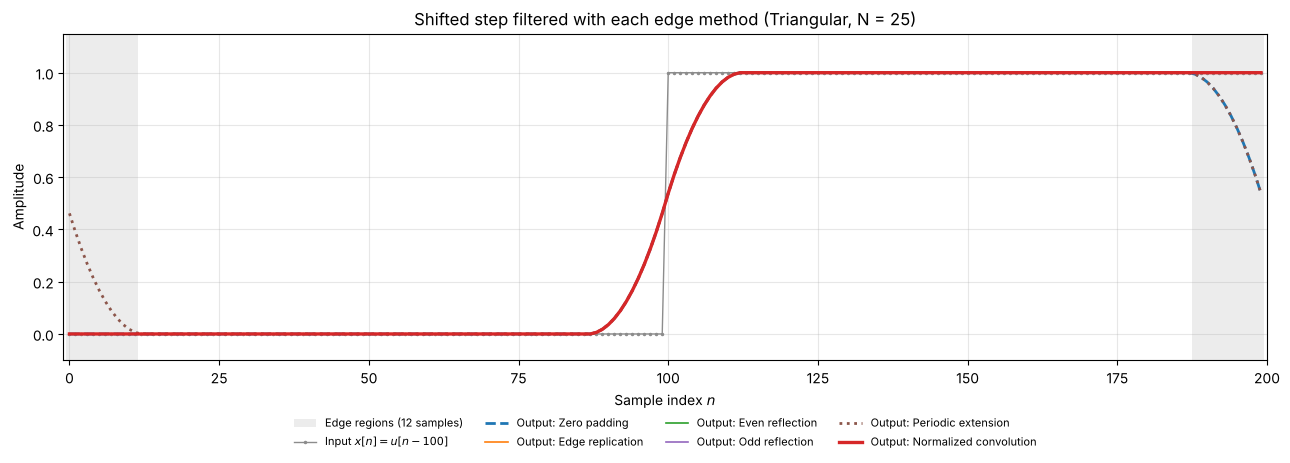

In [24]:
fig, ax = plt.subplots(figsize=(13, 4.8))
k = np.arange(L_e)
ax.axvspan(-0.5, M_e - 0.5, color="gray", alpha=0.15, lw=0)
ax.axvspan(L_e - M_e - 0.5, L_e - 0.5, color="gray", alpha=0.15, lw=0, label=f"Edge regions ({M_e} samples)")
ax.plot(k, x_step, color="0.55", lw=1.0, marker=".", ms=3, label="Input $x[n] = u[n-100]$")
for name, fn in edge_methods.items():
    ax.plot(k, fn(x_step, h_e), label=f"Output: {name}", **edge_styles[name])
ax.set_title(f"Shifted step filtered with each edge method ({edge_name}, N = {2*M_e+1})")
ax.set_xlabel("Sample index $n$")
ax.set_ylabel("Amplitude")
ax.set_xlim(-1, L_e)
ax.set_ylim(-0.1, 1.15)
ax.grid(True, alpha=0.3)
ax.legend(fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.14), ncol=4, frameon=False)
plt.tight_layout()
plt.show()

### Test 2: Monte Carlo on mean-1 white noise

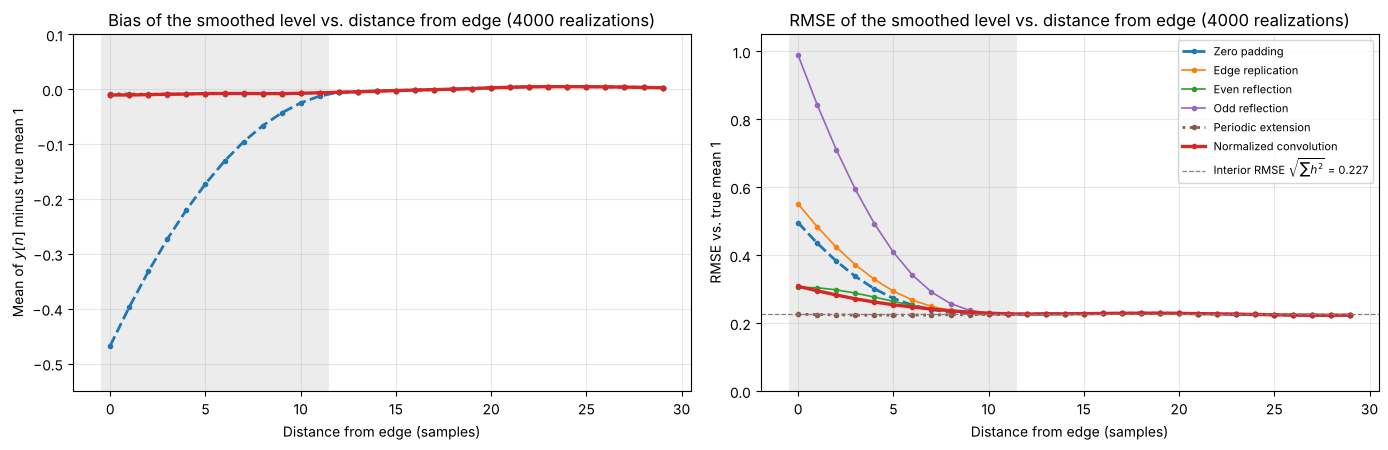

In [25]:
rng_mc = np.random.default_rng(7)
R = 4000
X_mc = 1.0 + rng_mc.standard_normal((R, L_e))          # mean 1, variance 1

mc = {}
for name, fn in edge_methods.items():
    Y = np.array([fn(x, h_e) for x in X_mc])
    mc[name] = dict(bias=Y.mean(axis=0) - 1.0,
                    rmse=np.sqrt(((Y - 1.0) ** 2).mean(axis=0)))

d = np.arange(2 * M_e + 6)          # distance from the left edge (results are symmetric at the right edge)
fig, ax = plt.subplots(1, 2, figsize=(14, 4.6))
for name in edge_methods:
    ax[0].plot(d, mc[name]["bias"][d], marker="o", ms=3, label=name, **edge_styles[name])
    ax[1].plot(d, mc[name]["rmse"][d], marker="o", ms=3, label=name, **edge_styles[name])
rmse_interior = np.sqrt(np.sum(h_e ** 2))
ax[1].axhline(rmse_interior, color="gray", ls="--", lw=0.9,
              label=f"Interior RMSE $\\sqrt{{\\sum h^2}}$ = {rmse_interior:.3f}")
for a, t, yl in zip(ax, ["Bias of the smoothed level", "RMSE of the smoothed level"],
                    ["Mean of $y[n]$ minus true mean 1", "RMSE vs. true mean 1"]):
    a.axvspan(-0.5, M_e - 0.5, color="gray", alpha=0.15, lw=0)
    a.set_title(f"{t} vs. distance from edge ({R} realizations)")
    a.set_xlabel("Distance from edge (samples)")
    a.set_ylabel(yl)
    a.grid(True, alpha=0.3)
ax[0].set_ylim(-0.55, 0.1)
ax[1].set_ylim(0, 1.05)
ax[1].legend(fontsize=8, loc="upper right")
plt.tight_layout()
plt.show()

### Test 3: Noise-free ramp

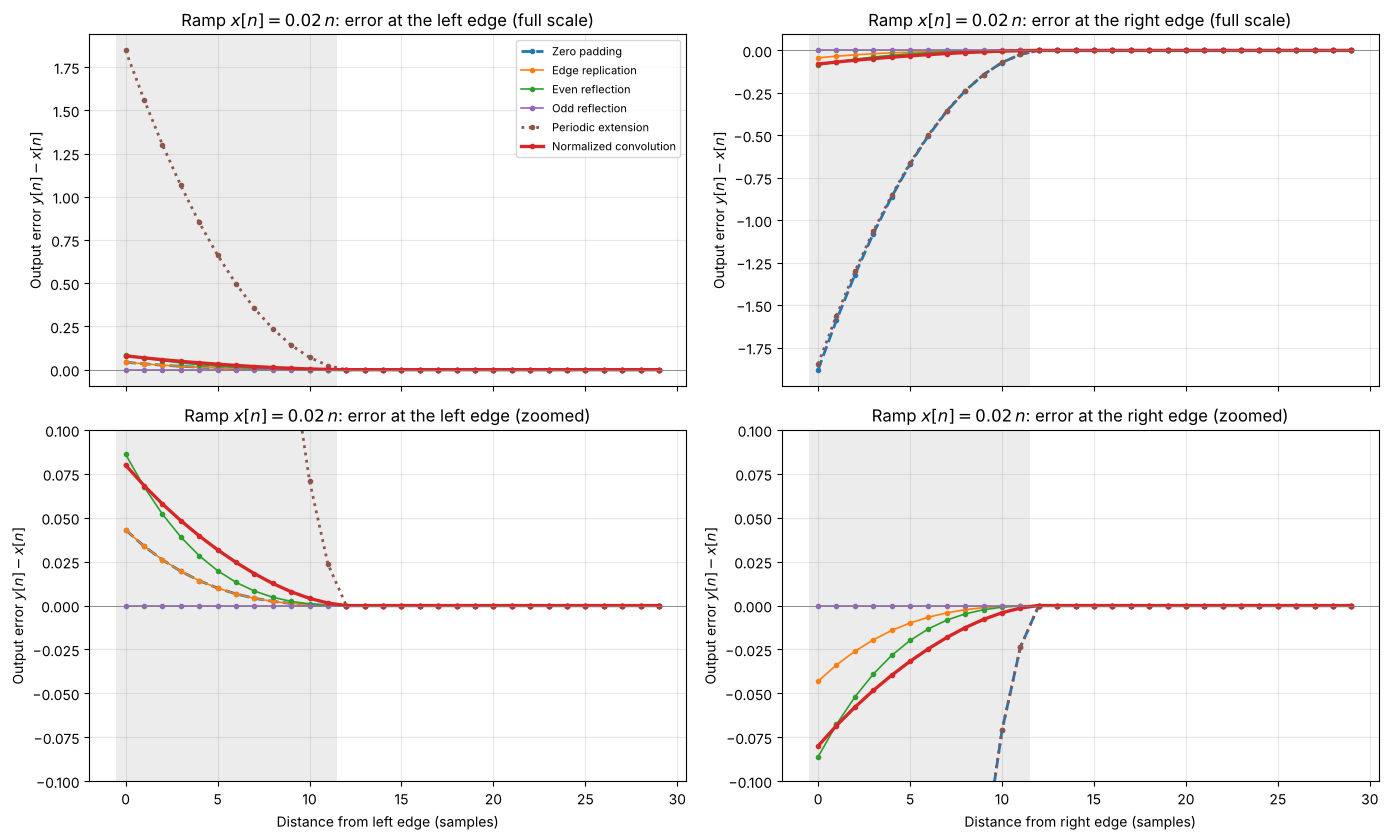

In [26]:
slope = 0.02
x_ramp = slope * np.arange(L_e)
ramp_err = {name: fn(x_ramp, h_e) - x_ramp for name, fn in edge_methods.items()}

fig, ax = plt.subplots(2, 2, figsize=(14, 8.5), sharex=True)
for name in edge_methods:
    left = ramp_err[name][d]                   # distance d from the left edge
    right = ramp_err[name][L_e - 1 - d]        # distance d from the right edge
    for row in range(2):
        ax[row, 0].plot(d, left, marker="o", ms=3, label=name, **edge_styles[name])
        ax[row, 1].plot(d, right, marker="o", ms=3, label=name, **edge_styles[name])
for (r, c), a in np.ndenumerate(ax):
    a.axvspan(-0.5, M_e - 0.5, color="gray", alpha=0.15, lw=0)
    a.axhline(0, color="gray", lw=0.6)
    a.set_ylabel("Output error $y[n] - x[n]$")
    a.grid(True, alpha=0.3)
    side = "left" if c == 0 else "right"
    a.set_title(f"Ramp $x[n] = {slope}\\,n$: error at the {side} edge" + (" (zoomed)" if r == 1 else " (full scale)"))
    if r == 1:
        a.set_ylim(-0.1, 0.1)
        a.set_xlabel(f"Distance from {side} edge (samples)")
ax[0, 0].legend(fontsize=8, loc="upper right")
plt.tight_layout()
plt.show()

### Summary table

In [27]:
print(f"{'Method':24s} {'Bias':>8s} {'RMSE':>7s} {'Ramp error':>11s} {'Ramp error':>11s}")
print(f"{'':24s} {'at n=0':>8s} {'at n=0':>7s} {'left end':>11s} {'right end':>11s}")
for name in edge_methods:
    print(f"{name:24s} {mc[name]['bias'][0]:+8.3f} {mc[name]['rmse'][0]:7.3f} "
          f"{ramp_err[name][0]:+11.3f} {ramp_err[name][-1]:+11.3f}")
print(f"\nInterior RMSE for reference: {rmse_interior:.3f}")

Method                       Bias    RMSE  Ramp error  Ramp error
                           at n=0  at n=0    left end   right end
Zero padding               -0.467   0.496      +0.043      -1.880
Edge replication           -0.011   0.551      +0.043      -0.043
Even reflection            -0.010   0.306      +0.086      -0.086
Odd reflection             -0.011   0.989      +0.000      +0.000
Periodic extension         -0.008   0.226      +1.846      -1.846
Normalized convolution     -0.010   0.308      +0.080      -0.080

Interior RMSE for reference: 0.227


### My recommendation: normalized convolution, with the edge samples flagged

**What the tests show**

- **Zero padding** is the worst choice for these signals. It assumes the missing samples are 0, so it pulls the output about halfway toward 0 at the edges: a bias of about $-0.47$ at $n = 0$ for mean-1 noise, and a drop to about 0.5 at the right end of the step. Its error on the ramp is small at the left end, where the ramp is near 0, but about $-1.9$ at the right end, where it is not.
- **Periodic extension** looks excellent on stationary noise, but only because a mean-1 noise record happens to "wrap around" smoothly. When the two ends differ (the step, the ramp), it mixes the end of the record into the beginning and causes errors of about $\pm 1.8$ on the ramp. (On the step, its right end coincides with zero padding, because the wrapped-in samples are the step's zeros.) This assumption is almost never true of real data.
- **Odd reflection** is the only method that reproduces the ramp exactly, because it extends the local trend. But at $n = 0$ it reduces to $y[0] = x[0]$: the reflected samples cancel the real ones, so **no smoothing happens at the endpoint**. The RMSE there is about 1.0, the raw noise level.
- **Edge replication** is unbiased on a constant level, but it puts all the missing weight on one sample, $x[0]$, so the endpoint RMSE rises to about 0.55. (It does have half the trend error of normalized convolution, about $\pm 0.04$ on the ramp.)
- **Even reflection** and **normalized convolution** perform almost identically: both are unbiased on a constant level, both have the lowest endpoint RMSE of the methods that also handle the step and the ramp (about 0.31, versus 0.23 in the interior), and both have only a small bias on the ramp.

**Why I prefer normalized convolution over even reflection**

The two tie on these tests, so I break the tie on principle and practicality:

1. **It doesn't invent data.** Every output is a weighted average of samples that actually exist. Even reflection uses some samples twice, which is a hidden assumption about the signal that the reader can't see.
2. **The DC gain is exactly 1 at every output sample,** by construction, not as a side effect of a symmetric extension.
3. **The output is guaranteed to stay within the range of the input,** because each output is a convex combination of input samples. Non-negative data (counts, intensities, concentrations) can never produce a negative smoothed value.
4. **It works for any filter length, even $N > L$.** In Problem 2 the binomial filter for $0.05\pi$ ($N = 113$) was longer than the 100-sample sinusoid. Reflection then needs to reflect repeatedly, which is hard to justify, whereas normalized convolution just uses whatever data exists.
5. **It handles missing samples or gaps the same way.** Give missing samples zero weight and renormalize. No other method here extends to gaps naturally.
6. **The highpass complement inherits it.** In Problem 3, $x - \text{(normalized lowpass)}$ has zero DC gain right up to the edges.
7. **It is cheap:** two convolutions, the second of which ($h * \mathbf{1}$) can be computed once and reused.

**This only works because $h[n] \ge 0$.** The denominator $\sum h[k]$ over the available taps is then always positive. For a frequency-selective filter with negative taps, the truncated tap sum can approach zero or change sign, and the renormalization breaks down (see Problem 5). This is a real advantage of the non-negative filter class.

**Limitations, and what I would do about them**

- **Trend bias.** With a one-sided window, the weighted average lies on the interior side of the endpoint, so a trend is biased at the edge by about (slope) $\times$ (centroid of the truncated window): $+0.08$ here for a slope of 0.02. This matters only when the change across $M$ samples is large compared with the noise. In that case, odd reflection or a local linear fit at the edges is better, at the cost of more noise.
- **Reduced smoothing.** Fewer samples are averaged near the edges, so the output is noisier there (RMSE 0.31 versus 0.23).
- **Flag the edge samples.** On plots and in downstream use, I would mark the first and last $M$ outputs as less reliable, as the shaded regions in Problem 2 do. If later processing needs uniform statistics and the record is long relative to $M$, the simplest honest option is to discard those $M$ samples at each end.

## Problem 5: What type of circumstances would you want to apply this type of filter, rather than a well-designed frequency selective filter? What are the design tradeoffs?

To make the tradeoffs concrete, I compare the Problem 2 smoothers designed for $\omega_c = 0.1\pi$ with an **equiripple (Parks-McClellan) lowpass filter** designed for the same $-3$ dB cutoff: passband edge $0.07\pi$, stopband edge $0.15\pi$, $N = 61$ taps. The equiripple design is optimal in the minimax sense, so it represents the best a frequency-selective FIR design can do at that length.

The time-domain tests use zero-phase (centered) filtering with edge replication for **every** filter, so the comparison is fair. (Normalized convolution can't be used for the equiripple filter because its taps go negative; see Problem 4.)

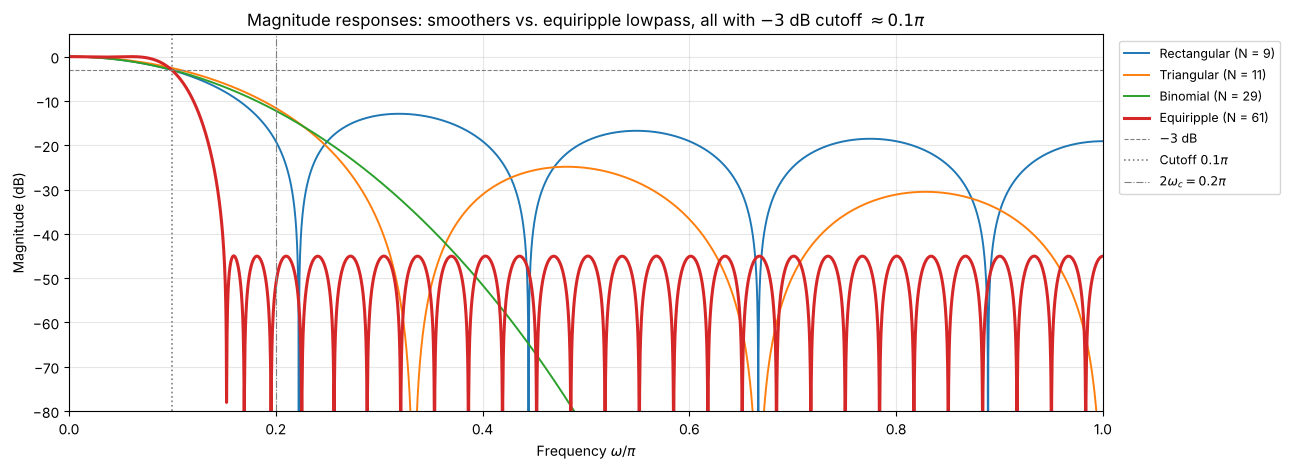

In [28]:
from scipy.signal import remez

# ---- Equiripple lowpass, centered at n = 0 like the other filters ----
N_eq = 61
h_eq = remez(N_eq, [0, 0.07, 0.15, 1.0], [1, 0], fs=2.0)   # band edges in units of pi
h_eq = h_eq / h_eq.sum()                                   # exact unit DC gain
M_eq = (N_eq - 1) // 2


def cutoff_from_taps(h):
    M = (len(h) - 1) // 2
    A = np.abs(amplitude_response(h, M, w_grid))
    return w_grid[np.argmax(A < 1 / np.sqrt(2))]


compare = {}
for name in filters:
    key = min(design[name], key=lambda t: abs(t - 0.1))
    compare[f"{name} (N = {2*design[name][key]+1})"] = filters[name](design[name][key])[1]
compare[f"Equiripple (N = {N_eq})"] = h_eq
cmp_colors = dict(zip(compare, ["C0", "C1", "C2", "C3"]))


def zero_phase_filter(x, h):
    return filter_padded(x, h, "edge")


# Non-negative test signal: pulses of different widths (e.g., event counts or intensities)
x_pulse = np.zeros(200)
x_pulse[40:43] = 1.0          # narrow pulse
x_pulse[90:110] = 1.0         # wide pulse
x_pulse[160] = 1.0            # single-sample impulse

fig, ax = plt.subplots(figsize=(13, 4.8))
for name, h in compare.items():
    M = (len(h) - 1) // 2
    A = amplitude_response(h, M, w_grid)
    ax.plot(w_grid / np.pi, 20 * np.log10(np.maximum(np.abs(A), 1e-6)), color=cmp_colors[name],
            lw=2.2 if "Equiripple" in name else 1.4, label=name)
ax.axhline(-3, color="gray", ls="--", lw=0.8, label="$-3$ dB")
ax.axvline(0.1, color="gray", ls=":", lw=1.2, label="Cutoff $0.1\\pi$")
ax.axvline(0.2, color="gray", ls="-.", lw=0.8, label="$2\\omega_c = 0.2\\pi$")
ax.set_title("Magnitude responses: smoothers vs. equiripple lowpass, all with $-3$ dB cutoff $\\approx 0.1\\pi$")
ax.set_xlabel("Frequency $\\omega/\\pi$")
ax.set_ylabel("Magnitude (dB)")
ax.set_xlim(0, 1)
ax.set_ylim(-80, 5)
ax.grid(True, alpha=0.3)
ax.legend(fontsize=9, loc="upper left", bbox_to_anchor=(1.01, 1.0))
plt.tight_layout()
plt.show()

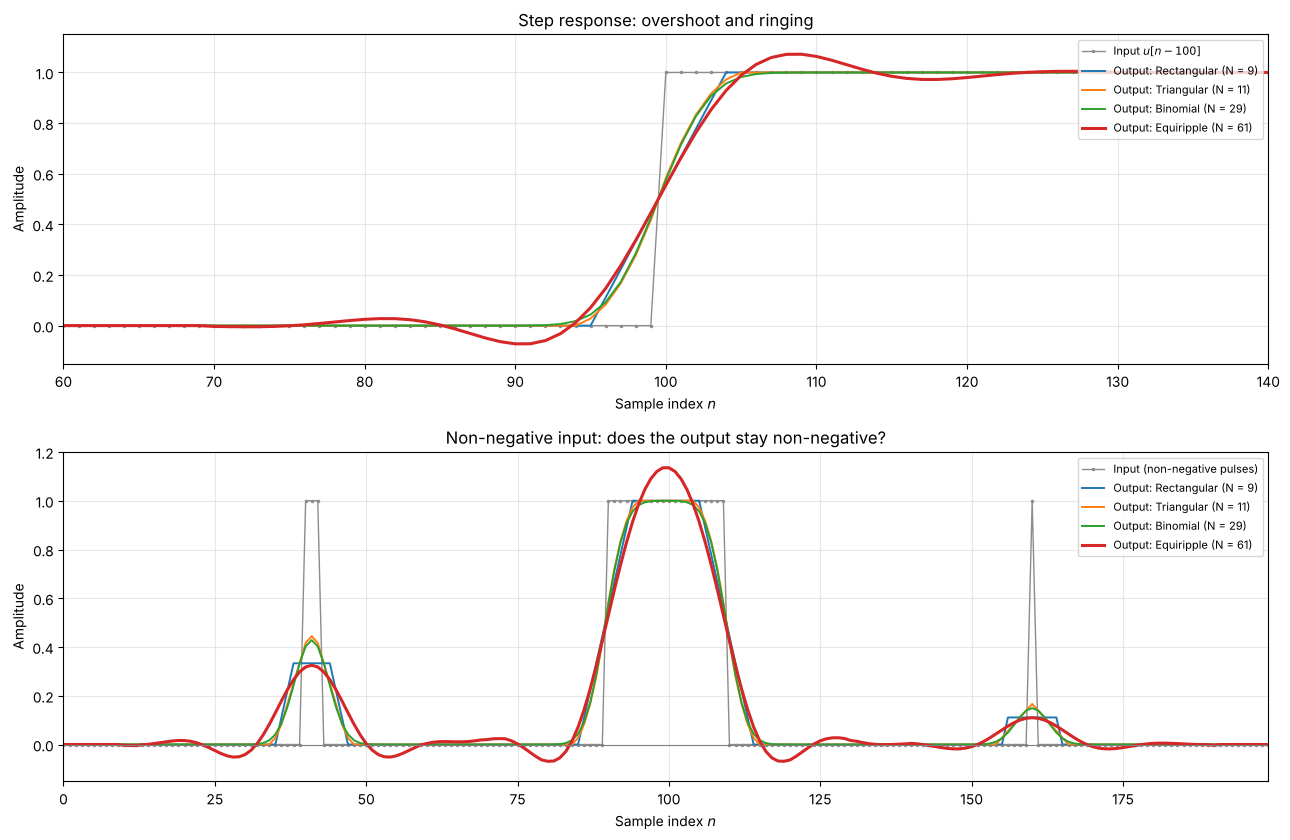

In [29]:
fig, ax = plt.subplots(2, 1, figsize=(13, 8.5))
k = np.arange(200)

a = ax[0]
a.plot(k, x_step, color="0.55", lw=1.0, marker=".", ms=3, label="Input $u[n-100]$")
for name, h in compare.items():
    a.plot(k, zero_phase_filter(x_step, h), color=cmp_colors[name],
           lw=2.2 if "Equiripple" in name else 1.4, label=f"Output: {name}")
a.set_title("Step response: overshoot and ringing")
a.set_xlim(60, 140)
a.set_ylim(-0.15, 1.15)

a = ax[1]
a.plot(k, x_pulse, color="0.55", lw=1.0, marker=".", ms=3, label="Input (non-negative pulses)")
for name, h in compare.items():
    a.plot(k, zero_phase_filter(x_pulse, h), color=cmp_colors[name],
           lw=2.2 if "Equiripple" in name else 1.4, label=f"Output: {name}")
a.axhline(0, color="gray", lw=0.8)
a.set_title("Non-negative input: does the output stay non-negative?")
a.set_xlim(0, 199)
a.set_ylim(-0.15, 1.2)

for a in ax:
    a.set_xlabel("Sample index $n$")
    a.set_ylabel("Amplitude")
    a.grid(True, alpha=0.3)
    a.legend(fontsize=8, loc="upper right")
plt.tight_layout()
plt.show()

In [30]:
def ops_per_output(name, N):
    # Arithmetic per output sample for an efficient implementation
    M = (N - 1) // 2
    if name.startswith("Rectangular"):
        return "2 adds, 1 scale (running sum)"
    if name.startswith("Triangular"):
        return "4 adds, 1 scale (two running sums)"
    if name.startswith("Binomial"):
        return f"{2*M} adds, 1 shift ([1,1] cascade)"
    return f"{M+1} mults, {N-1} adds (symmetric FIR)"


print(f"{'Filter':22s} {'-3 dB':>7s} {'Gain at':>8s} {'Atten. at':>10s} {'Step':>10s} {'Min output,':>12s}  Arithmetic per output")
print(f"{'':22s} {'cutoff':>7s} {'0.05π':>8s} {'0.2π (dB)':>10s} {'overshoot':>10s} {'pulse input':>12s}")
for name, h in compare.items():
    M = (len(h) - 1) // 2
    A = amplitude_response(h, M, w_grid)
    g05 = np.abs(amplitude_response(h, M, np.array([0.05 * np.pi])))[0]
    stop = 20 * np.log10(np.abs(A[w_grid >= 0.2 * np.pi]).max())
    ys = zero_phase_filter(x_step, h)
    yp = zero_phase_filter(x_pulse, h)
    print(f"{name:22s} {cutoff_from_taps(h)/np.pi:6.3f}π {g05:8.3f} {stop:10.1f} "
          f"{100*(ys.max()-1):9.1f}% {yp.min():+12.3f}  {ops_per_output(name, len(h))}")

Filter                   -3 dB  Gain at  Atten. at       Step  Min output,  Arithmetic per output
                        cutoff    0.05π  0.2π (dB)  overshoot  pulse input
Rectangular (N = 9)     0.099π    0.920      -12.9       0.0%       +0.000  2 adds, 1 scale (running sum)
Triangular (N = 11)     0.108π    0.930      -11.6       0.0%       +0.000  4 adds, 1 scale (two running sums)
Binomial (N = 29)       0.100π    0.917      -12.2       0.0%       +0.000  28 adds, 1 shift ([1,1] cascade)
Equiripple (N = 61)     0.099π    0.996      -45.0       7.2%       -0.069  31 mults, 60 adds (symmetric FIR)


### When to use a non-negative smoother instead of a frequency-selective filter

**What the comparison shows**

- **Frequency selectivity: the equiripple filter wins decisively.** At $2\omega_c = 0.2\pi$, it attenuates by about 45 dB; the smoothers manage only about 12 dB. The smoothers also droop well inside the passband: at $0.05\pi$, half the cutoff, they already pass only 0.92 to 0.93, versus about 1.0 for the equiripple filter.
- **Time-domain behavior: the smoothers win decisively.** Their step responses rise monotonically with **0% overshoot**, and for a non-negative input their output **never goes negative**. The equiripple filter overshoots the step by about 7%, rings on both sides of every edge, and produces negative values from an all-positive pulse train.
- **Cost:** the smoothers need a fraction of the arithmetic and essentially **no multiplies** (at most one final scaling per output). The equiripple filter needs 31 multiplies per output even with symmetry exploited.

**Why: the tradeoff is built into non-negative impulse responses.** If $h[n] \ge 0$, then
$$
|H(e^{j\omega})| = \Big|\sum_n h[n] e^{-j\omega n}\Big| \le \sum_n h[n] = H(e^{j0}) = 1,
$$
so the largest gain is always at DC, and these filters are inherently lowpass. More importantly, the output $y[n] = \sum_k h[k]\,x[n-k]$ is a **weighted average** of input samples, so it can never exceed the input's range. That rules out overshoot and ringing entirely. But a sharp, flat-passband frequency response requires an impulse response like $\frac{\sin(\omega_c n)}{\pi n}$, whose **negative lobes** are what produce the steep transition. So a filter can have either the sharp transition or the no-overshoot guarantee, not both: frequency selectivity and time-domain monotonicity pull in opposite directions.

**Circumstances that favor a non-negative smoother**

1. **The information is in the time-domain shape,** not in a frequency band: edges, peaks, step times, pulse widths, trends. Ringing would create false peaks or false crossings. Examples are threshold detection, event timing, and estimating a baseline or envelope.
2. **The signal is physically non-negative or bounded:** counts, intensities, pixel values, concentrations, probabilities, power. A smoother keeps the output physically meaningful. Gaussian and box blurs are the standard choice in image processing for this reason.
3. **The goal is a local average or trend,** with no hard frequency specification. The duration directly sets the averaging window, which is easy to explain and justify.
4. **Computation is tight:** embedded and FPGA systems, high-rate streams, or multiplier-free hardware. A moving average is a running sum; CIC decimators are cascaded moving averages for exactly this reason.
5. **Robustness matters:** normalized-convolution edge handling and gap handling (Problem 4) require $h \ge 0$, and a smoother's complement makes a simple, DC-exact detrending highpass filter (Problem 3).

**Circumstances that favor a frequency-selective filter**

1. **Two components are close in frequency** and must be separated, for example a signal band next to an interferer or a narrow 60 Hz line to remove.
2. **There is a stopband specification,** such as anti-aliasing before decimation where aliased energy must be below $-60$ dB, or channel selection in communications.
3. **The passband must be flat,** for example when amplitude accuracy matters within the band.
4. **The application needs bandpass or bandstop behavior,** which non-negative filters cannot provide, since their peak gain is always at DC.

**The design tradeoffs, summarized**

| | Non-negative smoother | Frequency-selective (e.g., equiripple) |
|---|---|---|
| Transition band | Wide; set by length | Narrow; set by length and spec |
| Stopband attenuation | Poor (rectangular about $-13$ dB sidelobes, triangular about $-26$ dB) | High; set by the design spec |
| Passband | Droops gradually | Flat within the ripple spec |
| Step response | Monotonic, no overshoot | Overshoot and ringing (about 7% here) |
| Output range | Always within the input range | Can exceed it, and can go negative |
| Design effort | One parameter (length or $\sigma$) | Band edges, ripple, weights, optimization |
| Cost | Can be multiplier-free | One multiply per pair of taps |
| Edge and gap handling | Normalized convolution works | Renormalization breaks down |

Within the smoother family the same tradeoff repeats on a smaller scale: the rectangular filter has the narrowest main lobe but the worst sidelobes, while the binomial filter has no sidelobes but needs the most taps for a given cutoff.

## Problem 6: Project.  Who is the problem important to and why? What would the impact be if you were successful in developing an accurate algorithm?

### Who the problem matters to

- **Transmission utilities and system operators.** Galloping can cause phase-to-phase flashovers, damaged hardware, and, in severe cases, structural failure. Today a utility usually learns of an event only after the damage is done. A live alert would tell operators which span is galloping while it is happening, so they can act on it (send crews, plan around repeated faults on that line) instead of reconstructing the event afterward.
- **Line designers and maintenance engineers.** Galloping is rare and hard to observe, so there is little measured data on real events: which mode, how large, and at what wind speed. Measured mode and amplitude records from real spans would let engineers check clearance designs against actual motion and judge whether anti-galloping countermeasures are working.
- **Researchers and standards groups.** Camera-based gallop measurement has been shown to work (Yang et al.; CIGRE ISH 2015), and the IEEE P2828 working group is writing a guide for it. The published work, however, says little about the discrete-time design decisions (decimation, filter type, window length, smoothing, alert logic) or how they trade accuracy against latency.

### Impact of an accurate algorithm

- **Inexpensive, non-contact monitoring.** A fixed camera becomes a gallop sensor, with no hardware installed on energized conductors.
- **Trustworthy alerts.** An alert that fires within a known latency and does **not** fire on blowout or ice shedding is one an operator can act on. False alarms matter as much as accuracy: an alert that cries wolf gets ignored.
- **Calibrated event records.** Mode number, frequency, and peak-to-peak amplitude in metres for every event, which is exactly the field data designers lack.
- **Design guidance.** Because every design choice is scored against simulator ground truth, the project shows which choices actually matter. That is useful to anyone building a similar monitor, including groups working on the P2828 guide.

## Problem 7: What is the problem?

### The problem

From video of a transmission span, estimate each conductor's galloping mode, frequency, and peak-to-peak amplitude, and raise or clear an alert, **quickly and without false alarms**. The input at each span station is a vertical-displacement sequence sampled at 30 fps,
$$
x[n] = \underbrace{\sum_k A_k[n]\,\phi_k\cos(\omega_k n + \theta_k)}_{\text{gallop}} + \underbrace{b[n]}_{\text{blowout}} + \underbrace{s[n]}_{\text{camera shake}} + \underbrace{v[n]}_{\text{noise}}.
$$
What makes this hard:

- **The bands are adjacent.** For the default 250 m span the gallop modes sit at $f_1 \approx 0.25$, $f_2 \approx 0.50$, and $f_3 \approx 0.76$ Hz. Blowout is quasi-static and sits just below $f_1$.
- **The measurement is coarse.** Resolution is about 0.21 m per pixel at midspan.
- **The alert has two competing requirements.** It must be fast (median latency ≤ 30 s, goal ≤ 15 s), yet never trigger on blowout alone or on an ice-shedding transient.

### Where non-negative FIR filters fit

This homework suggests that simple non-negative smoothers could do two jobs in my pipeline that I had planned to give to frequency-selective filters. Following Problem 5, the project question becomes: **where is a smoother good enough, and what do I give up?**

**1. Blowout rejection as "signal minus its smoothed version" (the Problem 3 highpass).**

My proposal compares a Kaiser-window FIR highpass (about 167 taps at 7.5 Hz, about 11 s delay) with a Butterworth IIR. Problem 3 suggests a third candidate: estimate the blowout with a moving average and subtract it. The physics makes this unusually effective. The gallop modes are harmonics, $f_n = n f_1$. A rectangular smoother one gallop period long, $L \approx f_s / f_1$, has zeros at exactly $f_1, 2f_1, 3f_1, \dots$. The smoothed signal therefore contains essentially no gallop, and the complement $1 - H(e^{j\omega})$ passes every mode with unit gain. Applying the complement twice,
$$
h_{\text{hp}}[n] = (\delta - h) * (\delta - h)[n], \qquad H_{\text{hp}}(e^{j\omega}) = \left(1 - H(e^{j\omega})\right)^2,
$$
doubles the stopband attenuation in dB near DC while keeping unit gain at the modes. For the default span ($f_1 = 0.252$ Hz, $f_s = 7.5$ Hz after decimation, $L = 29$, about 3.9 s):

| Metric | Proposal spec / Kaiser FIR | Period-matched $(1-H)^2$ |
|---|---|---|
| Attenuation at 0.05 Hz | ≥ 40 dB | 48.8 dB |
| Gain at $f_1$, $2f_1$, $3f_1$ | within ±0.5 dB | within ±0.5 dB |
| Gain at the 0.15 Hz passband edge | within ±0.5 dB | −13 dB |
| Largest gain between modes | ≤ +0.5 dB | +3.4 dB |
| Causal delay | ≈ 11 s | ≈ 3.7 s |
| Arithmetic per sample | ≈ 167-tap convolution | two running sums |

The trade-off matches Problem 5. The smoother fails the flat-passband specification, which is acceptable only because gallop energy sits at the harmonics. In exchange, it cuts the delay by about a factor of three, which directly helps the alert-latency requirement. It also depends on the predicted $f_1$: a 5 % error in $f_1$ costs about 1.4 dB at the fundamental. Rounding $L$ to an integer moves the nulls as well. $L = 29$ at 7.5 Hz puts them at 0.259 Hz (2.6 % high), while forming the trend at 30 Hz with $L = 119$ puts them within 0.1 % of $f_1$. Finally, a sudden gust leaves a residual that lasts about one smoother length, with no long ringing tail.

**2. Amplitude envelope for the alert.** The alert compares the gallop semi-amplitude with 0.75 m (raise) and 0.50 m (clear). I can square the high-pass output and smooth it with the same period-matched boxcar. The result is the mean square over exactly one fundamental period. The products between modes also land at multiples of $f_1$, so they fall in the nulls and the power estimate has almost no ripple. For a single sinusoidal mode, the semi-amplitude is $\sqrt{2}\,\text{RMS}$. Because the taps are non-negative with unit DC gain:

- the smoothed power is never negative and stays calibrated in m²;
- the step response is monotonic, so when the envelope jumps, the estimate rises to the new level without overshooting it.

A sharp lowpass with negative taps would overshoot on a step and could briefly cross the threshold, for example after an ice-shedding transient. That makes this choice directly relevant to the zero-false-alert requirement. The delay is about 2 s (centred) or 4 s (causal), compared with a 16 s STFT window. One caveat: real gallop orbits are asymmetric (the conductor rises about three times as far as it falls), so $\sqrt{2}\,\text{RMS}$ is not exactly half the peak-to-peak amplitude. The ground truth will show how large that bias is.

**3. Smoothed PSDs without segmenting.** As the extended-deadline email pointed out, Welch's method can fail when the record is cut into segments. An alternative for the PSD requirement (F7) is to smooth one long periodogram **across frequency** with a non-negative, unit-sum kernel (the Daniell approach). Non-negative taps keep the PSD estimate non-negative, and the unit sum approximately preserves total power.

## Problem 8: What instrumentation or data do you have available to support this project?

### Data

- **Physics-based synthetic video generator.** I built this before the proposal as Step 1 of the gallop-monitoring effort. It renders a 250 m span of Drake ACSR with 6 mm of glaze ice, plus a steel shield wire. A calibrated pinhole camera views the span broadside at 1280 × 720 and 30 fps. Gallop follows coupled Den Hartog dynamics under a scripted wind schedule (4 → 16 m/s and back). Blowout, turbulent gusts, ice shedding, weather, camera shake, and sensor noise can each be switched on or off.
- **Exact per-frame ground truth.** Each run writes a CSV of modal coordinates, displacements, pixel positions at 25, 50, and 75 % of the span, amplitude envelopes, and alert labels. It also writes `metadata.json` with the camera matrices (K, R, t), conductor properties, sag, and modal frequencies. Because the modal coordinates are logged, I can compare the high-pass output with the true gallop component sample by sample. I can also check the period-matched smoother against the true $f_1$.
- **Scenario matrix S1–S8.** These isolate each confounder:
  - S5 (blowout only) tests the blowout residual of the high-pass designs.
  - S6 (ice shedding) tests whether a transient can cause a false alert.
  - S3 (stepped amplitude) is a direct test of the envelope smoother's step response and overshoot.
  - S8 repeats the nominal case over 10 random seeds, giving the variance of every metric.
- **Test signals.** I can inject sinusoids of known frequency and amplitude, plus steps, to verify filter responses and spectral scaling, the same way I checked the periodogram scaling in this homework.
- **Reference data.** The EPRI Orange Book provides field statistics (mode counts, orbit shape) and empirical amplitude relations (Hunt–Richards, Lilien–Havard) as sanity checks on simulated amplitudes.

### Instrumentation and tools

- Python 3.10+ with NumPy, SciPy, and OpenCV on a laptop or desktop. Each filter and spectral step is written out directly and checked against `scipy.signal`.
- A function generator and oscilloscope on my home bench. These could drive and verify a small vibrating-wire rig if I pursue the bench-rig stretch goal.

### What is not available

No real gallop footage with ground truth exists to my knowledge, so the quantitative evaluation relies on the simulator. I will frame results as relative comparisons between designs rather than absolute field performance.

## Problem 9: How do you plan to display your results. What tables or figures will you include?

All results will be in physical units (metres, hertz, seconds) and scored against the simulator ground truth.

### Figures

1. **Blowout-filter comparison:**
   - magnitude response (dB) of the Kaiser FIR, the Butterworth IIR, and the period-matched $(1-H)^2$ filter, overlaid on the specification mask, with $f_1$, $f_2$, and $f_3$ marked;
   - group delay of each design;
   - impulse responses;
   - a pole–zero plot for the IIR design.
2. **Time-domain example at one span station:**
   - raw displacement and the smoothed blowout estimate;
   - high-pass output overlaid on the true gallop component;
   - edge regions shaded, as in this homework.
3. **Spectrogram:** the STFT with the true modal frequencies overlaid, showing gallop growing and dying away with the wind schedule.
4. **PSD comparison over a steady-gallop interval:** raw periodogram, frequency-smoothed (Daniell) periodogram, and Welch estimate on the same axes.
5. **Envelope and alerts:**
   - estimated semi-amplitude from the boxcar-smoothed power, the Hilbert envelope, and the STFT, against the ground-truth envelope;
   - the 0.75 m and 0.50 m thresholds;
   - estimated and true alert raise/clear times.

   I will show this for the stepped-amplitude scenario (S3) and the ice-shedding scenario (S6).
6. **Latency–accuracy trade-off:** median alert latency against RMS amplitude error for each filter and smoother design and each window length.
7. **Sensitivity of the period-matched filter:** gain at $f_1$ against the error in the predicted $f_1$.

### Tables

1. **Filter-specification compliance** for each design:
   - attenuation at 0.05 Hz;
   - passband ripple;
   - gain at $f_1$–$f_3$;
   - delay;
   - arithmetic per sample.
2. **Performance metrics** P1–P7 for each scenario (S1–S7) and each blowout filter, with pass/fail against the targets.
3. **Monte Carlo results (S8):** mean ± standard deviation of every metric over 10 seeds.

## Problem 10: What, if anything, did you learn from this homework?

## Problem 11: What new questions, if any, do you have?